# RATA-MAR-SI v2.1 — Publication-Safe Complete Pipeline

**Goal:** produce manuscript-ready results for the Special Issue using the verified original UTD-MHAD Skeleton + IMU data.

### What v2.1 fixes
1. Development uses **subjects 1,3,5 → train; subject 7 → validation** only. Official test subjects **2,4,6,8 stay locked** until the final section.
2. Noise/joint-drop evaluation is **deterministic and paired**: every model sees the same corrupted samples for a given corruption seed.
3. Final multi-seed training sets the seed **before model construction**, fixing weight-initialization reproducibility.
4. Final results report **mean ± standard deviation across training seeds**; stochastic corruptions also use repeated fixed corruption seeds.
5. Adds final ablations, confusion matrix, per-class report, reliability diagnostics, efficiency profiling, publication-ready CSV/PNG outputs.

**Architecture is intentionally unchanged from v2.** This notebook improves experimental validity rather than adding new modules.

## 1 — Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2 — Paths and run configuration

In [2]:
from pathlib import Path
import sys, shutil, json, os, platform, time

PROJECT = Path('/content/drive/MyDrive/RATA_IASC')
PROCESSED = PROJECT / 'processed/UTD_MHAD_original_SI'
MANIFEST = PROCESSED / 'manifest_27class.csv'
SK_NPY = PROCESSED / 'utd_mhad_skeleton_T64_f16.npy'
IMU_NPY = PROCESSED / 'utd_mhad_inertial_T64_f16.npy'

RUNS = PROJECT / 'runs/RATA_MAR_SI_v21'
SRC = PROJECT / 'src_rata_mar_si_v21'
FIGS = RUNS / 'figures'
TABLES = RUNS / 'tables'
FINAL_MODELS = RUNS / 'final_models'
for p in [RUNS,SRC,FIGS,TABLES,FINAL_MODELS]: p.mkdir(parents=True,exist_ok=True)

for p in [MANIFEST,SK_NPY,IMU_NPY]:
    print(p, 'exists =', p.exists())
    assert p.exists(), f'Missing verified processed file: {p}'

DEV_SEED = 42
DEV_EPOCHS = 40
FINAL_EPOCHS = 100
FINAL_SEEDS = [0,1,2]
CORRUPTION_SEEDS = [1103, 2207, 3301, 4409, 5519]
LR = 3e-4
BATCH = 64
FORCE_RETRAIN_DEV = False
RUN_DEVELOPMENT_ABLATION = True
RUN_FINAL = True
RUN_FINAL_ABLATION = True
RUN_EFFICIENCY = True

print('RUNS:',RUNS)
print('Final seeds:',FINAL_SEEDS)
print('Corruption seeds:',CORRUPTION_SEEDS)

/content/drive/MyDrive/RATA_IASC/processed/UTD_MHAD_original_SI/manifest_27class.csv exists = True
/content/drive/MyDrive/RATA_IASC/processed/UTD_MHAD_original_SI/utd_mhad_skeleton_T64_f16.npy exists = True
/content/drive/MyDrive/RATA_IASC/processed/UTD_MHAD_original_SI/utd_mhad_inertial_T64_f16.npy exists = True
RUNS: /content/drive/MyDrive/RATA_IASC/runs/RATA_MAR_SI_v21
Final seeds: [0, 1, 2]
Corruption seeds: [1103, 2207, 3301, 4409, 5519]


## 3 — Environment

In [3]:
!pip install -q pandas scikit-learn matplotlib thop

import numpy as np, pandas as pd, torch, matplotlib, sklearn
print('Python:',platform.python_version())
print('Torch :',torch.__version__)
print('CUDA  :',torch.version.cuda)
print('GPU   :',torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)
assert torch.cuda.is_available(), 'Enable a GPU runtime in Colab.'

Python: 3.13.15
Torch : 2.11.0+cu128
CUDA  : 12.8
GPU   : NVIDIA A100-SXM4-40GB


## 4 — Write v2.1 source modules

In [4]:
import py_compile
source_files = {
    SRC/'models_v21.py': '\nfrom __future__ import annotations\n\nimport math\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\n\nBONES_20 = [\n    (0,1),(1,2),(2,3),\n    (2,4),(4,5),(5,6),(6,7),\n    (2,8),(8,9),(9,10),(10,11),\n    (0,12),(12,13),(13,14),(14,15),\n    (0,16),(16,17),(17,18),(18,19),\n]\n\n\ndef adjacency20():\n    A = torch.eye(20)\n    for i, j in BONES_20:\n        A[i, j] = 1.0\n        A[j, i] = 1.0\n    d = A.sum(1).clamp_min(1.0)\n    D = torch.diag(d.pow(-0.5))\n    return D @ A @ D\n\n\nclass STGCNBlock(nn.Module):\n    def __init__(self, c1, c2, dropout=0.1):\n        super().__init__()\n        self.register_buffer("A", adjacency20())\n        self.gcn = nn.Conv2d(c1, c2, 1, bias=False)\n        self.tcn = nn.Conv2d(c2, c2, (5, 1), padding=(2, 0), bias=False)\n        self.bn = nn.BatchNorm2d(c2)\n        self.drop = nn.Dropout(dropout)\n        self.act = nn.ReLU(inplace=True)\n        self.res = nn.Identity() if c1 == c2 else nn.Sequential(\n            nn.Conv2d(c1, c2, 1, bias=False),\n            nn.BatchNorm2d(c2),\n        )\n\n    def forward(self, x):\n        residual = self.res(x)\n        x = torch.einsum("vw,bctw->bctv", self.A, x)\n        x = self.gcn(x)\n        x = self.tcn(x)\n        x = self.drop(self.bn(x))\n        return self.act(x + residual)\n\n\nclass SkeletonEncoder(nn.Module):\n    def __init__(self, dim=256, tokens=8):\n        super().__init__()\n        self.net = nn.Sequential(\n            STGCNBlock(3, 64),\n            STGCNBlock(64, 128),\n            STGCNBlock(128, dim),\n        )\n        self.tokens = int(tokens)\n\n    def forward(self, x):\n        # x: [B,T,20,3] -> [B,3,T,20]\n        x = x.permute(0, 3, 1, 2)\n        x = self.net(x).mean(-1)                 # [B,D,T]\n        x = F.adaptive_avg_pool1d(x, self.tokens)\n        return x.transpose(1, 2)                 # [B,tokens,D]\n\n\nclass IMUEncoder(nn.Module):\n    def __init__(self, dim=256, tokens=8):\n        super().__init__()\n        self.net = nn.Sequential(\n            nn.Conv1d(6, 64, 7, padding=3, bias=False),\n            nn.BatchNorm1d(64), nn.GELU(),\n            nn.Conv1d(64, 128, 5, padding=2, bias=False),\n            nn.BatchNorm1d(128), nn.GELU(),\n            nn.Conv1d(128, dim, 3, padding=1, bias=False),\n            nn.BatchNorm1d(dim), nn.GELU(),\n        )\n        self.tokens = int(tokens)\n\n    def forward(self, x):\n        x = self.net(x.transpose(1, 2))           # [B,D,T]\n        x = F.adaptive_avg_pool1d(x, self.tokens)\n        return x.transpose(1, 2)                  # [B,tokens,D]\n\n\ndef _pool_scalar_sequence(x, tokens):\n    # x: [B,T]\n    return F.adaptive_avg_pool1d(x.unsqueeze(1), tokens).transpose(1, 2)  # [B,tokens,1]\n\n\ndef skeleton_quality_descriptors(sk, tokens=8):\n    # Energy and temporal-difference energy. Missing skeleton => both near zero.\n    energy = sk.abs().mean(dim=(2, 3))  # [B,T]\n    diff = torch.zeros_like(energy)\n    diff[:, 1:] = (sk[:, 1:] - sk[:, :-1]).abs().mean(dim=(2, 3))\n    return torch.cat([\n        _pool_scalar_sequence(energy, tokens),\n        _pool_scalar_sequence(diff, tokens),\n    ], dim=-1)  # [B,tokens,2]\n\n\ndef imu_quality_descriptors(imu, tokens=8):\n    energy = imu.abs().mean(dim=2)\n    diff = torch.zeros_like(energy)\n    diff[:, 1:] = (imu[:, 1:] - imu[:, :-1]).abs().mean(dim=2)\n    return torch.cat([\n        _pool_scalar_sequence(energy, tokens),\n        _pool_scalar_sequence(diff, tokens),\n    ], dim=-1)\n\n\nclass SinusoidalTemporalEncoding(nn.Module):\n    def __init__(self, dim=256, max_tokens=64):\n        super().__init__()\n        pe = torch.zeros(max_tokens, dim)\n        pos = torch.arange(max_tokens, dtype=torch.float32).unsqueeze(1)\n        div = torch.exp(\n            torch.arange(0, dim, 2, dtype=torch.float32)\n            * (-math.log(10000.0) / dim)\n        )\n        pe[:, 0::2] = torch.sin(pos * div)\n        pe[:, 1::2] = torch.cos(pos * div)\n        self.register_buffer("pe", pe.unsqueeze(0), persistent=False)\n\n    def forward(self, x):\n        return x + self.pe[:, :x.shape[1]].to(dtype=x.dtype, device=x.device)\n\n\nclass IntrinsicReliability(nn.Module):\n    """\n    Predicts modality quality BEFORE cross-modal alignment.\n    Receives only the modality\'s own feature tokens + simple raw-input quality descriptors.\n    """\n    def __init__(self, dim=256, desc_dim=2):\n        super().__init__()\n        hidden = max(64, dim // 2)\n        self.net = nn.Sequential(\n            nn.LayerNorm(dim + desc_dim),\n            nn.Linear(dim + desc_dim, hidden),\n            nn.GELU(),\n            nn.Dropout(0.1),\n            nn.Linear(hidden, 1),\n        )\n\n    def forward(self, tokens, descriptors):\n        return self.net(torch.cat([tokens, descriptors], dim=-1))\n\n\nclass ReliabilityGatedTemporalAlign(nn.Module):\n    """\n    Bidirectional cross-modal temporal alignment.\n    Positional encoding is applied before attention.\n    Cross-modal residual is gated by the OTHER modality\'s pre-alignment reliability.\n    """\n    def __init__(self, dim=256, heads=4, dropout=0.1):\n        super().__init__()\n        self.pos = SinusoidalTemporalEncoding(dim)\n        self.ns = nn.LayerNorm(dim)\n        self.ni = nn.LayerNorm(dim)\n        self.s_queries_i = nn.MultiheadAttention(\n            dim, heads, batch_first=True, dropout=dropout\n        )\n        self.i_queries_s = nn.MultiheadAttention(\n            dim, heads, batch_first=True, dropout=dropout\n        )\n        self.out_s = nn.Sequential(nn.Linear(dim, dim), nn.GELU())\n        self.out_i = nn.Sequential(nn.Linear(dim, dim), nn.GELU())\n\n    def forward(self, s, i, r_s, r_i):\n        sp = self.pos(self.ns(s))\n        ip = self.pos(self.ni(i))\n\n        ds, A_si = self.s_queries_i(\n            query=sp, key=ip, value=i,\n            need_weights=True, average_attn_weights=True\n        )\n        di, A_is = self.i_queries_s(\n            query=ip, key=sp, value=s,\n            need_weights=True, average_attn_weights=True\n        )\n\n        # Avoid a bad/missing modality contaminating the good branch.\n        s_out = s + r_i * self.out_s(ds)\n        i_out = i + r_s * self.out_i(di)\n\n        return s_out, i_out, A_si, A_is\n\n\nclass LateFusionSI(nn.Module):\n    def __init__(self, nc=27, dim=256):\n        super().__init__()\n        self.sk = SkeletonEncoder(dim)\n        self.im = IMUEncoder(dim)\n        self.head = nn.Sequential(\n            nn.LayerNorm(dim * 2),\n            nn.Linear(dim * 2, dim),\n            nn.GELU(),\n            nn.Dropout(0.2),\n            nn.Linear(dim, nc),\n        )\n\n    def forward(self, sk, imu):\n        s = self.sk(sk).mean(1)\n        i = self.im(imu).mean(1)\n        return {"logits": self.head(torch.cat([s, i], dim=-1))}\n\n\nclass SkeletonOnly(nn.Module):\n    def __init__(self, nc=27, dim=256):\n        super().__init__()\n        self.enc = SkeletonEncoder(dim)\n        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, nc))\n\n    def forward(self, sk, imu):\n        z = self.enc(sk)\n        return {"logits": self.head(z.mean(1))}\n\n\nclass IMUOnly(nn.Module):\n    def __init__(self, nc=27, dim=256):\n        super().__init__()\n        self.enc = IMUEncoder(dim)\n        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, nc))\n\n    def forward(self, sk, imu):\n        z = self.enc(imu)\n        return {"logits": self.head(z.mean(1))}\n\n\nclass RATAMAR_SI_v2(nn.Module):\n    """\n    RATA-MAR-SI v2.1 (architecture unchanged)\n\n    Key changes vs v1:\n    1) reliability estimated BEFORE cross-modal alignment,\n    2) temporal positional encoding,\n    3) reliability-gated cross-modal residuals,\n    4) auxiliary unimodal classification heads,\n    5) normalized positive reliability fusion.\n    """\n    def __init__(\n        self,\n        nc=27,\n        dim=256,\n        tokens=8,\n        heads=4,\n        transformer_layers=2,\n        fusion_temperature=0.7,\n        use_alignment=True,\n        use_reliability=True,\n    ):\n        super().__init__()\n        self.tokens = tokens\n        self.use_alignment = bool(use_alignment)\n        self.use_reliability = bool(use_reliability)\n        self.temp = float(fusion_temperature)\n\n        self.sk = SkeletonEncoder(dim, tokens=tokens)\n        self.im = IMUEncoder(dim, tokens=tokens)\n\n        self.rel_s = IntrinsicReliability(dim)\n        self.rel_i = IntrinsicReliability(dim)\n        self.align = ReliabilityGatedTemporalAlign(dim, heads)\n\n        layer = nn.TransformerEncoderLayer(\n            d_model=dim,\n            nhead=heads,\n            dim_feedforward=dim * 4,\n            dropout=0.1,\n            activation="gelu",\n            batch_first=True,\n            norm_first=True,\n        )\n        self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)\n\n        self.aux_s = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, nc))\n        self.aux_i = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, nc))\n        self.main_head = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, nc))\n\n    def forward(self, sk, imu):\n        s = self.sk(sk)\n        i = self.im(imu)\n\n        d_s = skeleton_quality_descriptors(sk, self.tokens)\n        d_i = imu_quality_descriptors(imu, self.tokens)\n\n        if self.use_reliability:\n            logit_s = self.rel_s(s, d_s)\n            logit_i = self.rel_i(i, d_i)\n            r_s = torch.sigmoid(logit_s)\n            r_i = torch.sigmoid(logit_i)\n        else:\n            logit_s = torch.zeros(\n                s.shape[0], s.shape[1], 1, device=s.device, dtype=s.dtype\n            )\n            logit_i = torch.zeros_like(logit_s)\n            r_s = torch.ones_like(logit_s)\n            r_i = torch.ones_like(logit_i)\n\n        # IMPORTANT: reliability is measured on uncontaminated modality features.\n        aux_s_logits = self.aux_s(s.mean(1))\n        aux_i_logits = self.aux_i(i.mean(1))\n\n        if self.use_alignment:\n            s_aligned, i_aligned, A_si, A_is = self.align(s, i, r_s, r_i)\n        else:\n            s_aligned, i_aligned = s, i\n            B, T = s.shape[:2]\n            eye = torch.eye(T, device=s.device, dtype=s.dtype).unsqueeze(0).expand(B, -1, -1)\n            A_si = eye\n            A_is = eye\n\n        # Positive quality weights. Softmax(log(r)) is equivalent to normalized\n        # positive reliability with temperature control.\n        eps = 1e-4\n        rel_log = torch.cat([\n            torch.log(r_s.clamp_min(eps)),\n            torch.log(r_i.clamp_min(eps)),\n        ], dim=-1)\n        alpha = torch.softmax(rel_log / self.temp, dim=-1)\n\n        fused = (\n            alpha[..., 0:1] * s_aligned\n            + alpha[..., 1:2] * i_aligned\n        )\n\n        fused = self.temporal(fused)\n        logits = self.main_head(fused.mean(1))\n\n        return {\n            "logits": logits,\n            "aux_skel_logits": aux_s_logits,\n            "aux_imu_logits": aux_i_logits,\n            "r_skel": r_s,\n            "r_imu": r_i,\n            "rel_logit_skel": logit_s,\n            "rel_logit_imu": logit_i,\n            "alpha": alpha,\n            "align_skel_to_imu": A_si,\n            "align_imu_to_skel": A_is,\n        }\n',
    SRC/'train_v21.py': 'from __future__ import annotations\n\nimport io\nimport json\nimport random\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nimport torch\nimport torch.nn.functional as F\nfrom sklearn.metrics import accuracy_score, f1_score\nfrom torch.utils.data import Dataset, DataLoader\n\n\ndef seed_everything(seed: int = 0):\n    """Seed Python/NumPy/PyTorch. Call this BEFORE model construction."""\n    seed = int(seed)\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n    # Prefer repeatability over benchmark auto-tuning.\n    torch.backends.cudnn.benchmark = False\n    torch.backends.cudnn.deterministic = True\n    return seed\n\n\ndef _seed_worker(worker_id):\n    worker_seed = torch.initial_seed() % 2**32\n    np.random.seed(worker_seed)\n    random.seed(worker_seed)\n\n\nclass UTDataset(Dataset):\n    def __init__(self, df, sk_npy, imu_npy):\n        self.df = df.reset_index(drop=True).copy()\n        self.sk = np.load(sk_npy, mmap_mode=\'r\')\n        self.im = np.load(imu_npy, mmap_mode=\'r\')\n\n    def __len__(self):\n        return len(self.df)\n\n    def __getitem__(self, idx):\n        row = self.df.iloc[idx]\n        ridx = int(row.row_index)\n        return {\n            \'skeleton\': torch.from_numpy(np.asarray(self.sk[ridx], dtype=np.float32)),\n            \'imu\': torch.from_numpy(np.asarray(self.im[ridx], dtype=np.float32)),\n            \'label\': torch.tensor(int(row.label), dtype=torch.long),\n            \'sample_id\': str(row.sample_id),\n            \'subject\': torch.tensor(int(row.subject), dtype=torch.long),\n        }\n\n\ndef make_loader(df, sk_npy, imu_npy, batch=64, shuffle=False, workers=2, seed=0):\n    g = torch.Generator()\n    g.manual_seed(int(seed))\n    return DataLoader(\n        UTDataset(df, sk_npy, imu_npy),\n        batch_size=batch,\n        shuffle=shuffle,\n        num_workers=workers,\n        pin_memory=True,\n        persistent_workers=workers > 0,\n        generator=g,\n        worker_init_fn=_seed_worker,\n    )\n\n\ndef subject_disjoint_dev_split(manifest_csv, val_subject=7):\n    """Development only: train odd subjects except val; validate on one unseen odd subject."""\n    df = pd.read_csv(manifest_csv)\n    odd = [1, 3, 5, 7]\n    train_subjects = [s for s in odd if s != int(val_subject)]\n    train = df[df.subject.isin(train_subjects)].copy()\n    val = df[df.subject == int(val_subject)].copy()\n    official_test = df[df.subject.isin([2, 4, 6, 8])].copy()\n    print(\'Publication-safe development split\')\n    print(\' train subjects:\', train_subjects, \'N=\', len(train))\n    print(\' val subject   :\', val_subject, \'N=\', len(val))\n    print(\' locked test   :\', [2,4,6,8], \'N=\', len(official_test), \'(DO NOT USE during development)\')\n    return train, val, official_test\n\n\ndef official_train_test(manifest_csv):\n    df = pd.read_csv(manifest_csv)\n    train = df[df.subject.isin([1,3,5,7])].copy()\n    test = df[df.subject.isin([2,4,6,8])].copy()\n    return train, test\n\n\ndef temporal_delay_zero_pad(x, shift):\n    """Non-circular temporal delay. Positive = delayed, negative = advanced."""\n    if isinstance(shift, int):\n        shifts = torch.full((x.shape[0],), shift, device=x.device, dtype=torch.long)\n    else:\n        shifts = shift.to(device=x.device, dtype=torch.long)\n    out = torch.zeros_like(x)\n    T = x.shape[1]\n    for b, s in enumerate(shifts.tolist()):\n        if s == 0:\n            out[b] = x[b]\n        elif s > 0:\n            if s < T:\n                out[b, s:] = x[b, :T-s]\n        else:\n            k = -s\n            if k < T:\n                out[b, :T-k] = x[b, k:]\n    return out\n\n\ndef corrupt_dual_view(sk, imu):\n    """Random corruption for TRAINING augmentation only."""\n    B = sk.shape[0]\n    device = sk.device\n    im0 = imu\n    sk = sk.clone()\n    imu = imu.clone()\n    q = torch.ones(B, 2, device=device)\n\n    for b in range(B):\n        u = random.random()\n        if u < 0.10:\n            sk[b].zero_(); q[b,0] = 0.0\n        elif u < 0.25:\n            mask = torch.rand(sk.shape[2], device=device) < 0.30\n            sk[b, :, mask, :] = 0; q[b,0] = 0.60\n        elif u < 0.40:\n            sk[b] += 0.08 * torch.randn_like(sk[b]); q[b,0] = 0.65\n\n        u = random.random()\n        if u < 0.10:\n            imu[b].zero_(); q[b,1] = 0.0\n        elif u < 0.25:\n            start = random.randint(0, max(0, imu.shape[1]-16))\n            imu[b, start:start+16] = 0; q[b,1] = 0.60\n        elif u < 0.40:\n            imu[b] += 0.20 * torch.randn_like(imu[b]); q[b,1] = 0.65\n\n        if q[b,0] == 0 and q[b,1] == 0:\n            imu[b] = im0[b]\n            q[b,1] = 1.0\n\n    shifts = torch.zeros(B, device=device, dtype=torch.long)\n    delay_mask = torch.rand(B, device=device) < 0.35\n    choices = torch.tensor([-16,-8,-4,4,8,16], device=device)\n    if delay_mask.any():\n        pick = torch.randint(0, len(choices), (int(delay_mask.sum().item()),), device=device)\n        shifts[delay_mask] = choices[pick]\n        imu = temporal_delay_zero_pad(imu, shifts)\n    return sk, imu, q, shifts\n\n\ndef weighted_ce(logits, y, quality):\n    per = F.cross_entropy(logits, y, reduction=\'none\')\n    denom = quality.sum().clamp_min(1.0)\n    return (per * quality).sum() / denom\n\n\ndef reliability_loss(out, q):\n    pred = torch.cat([out[\'r_skel\'].mean(1), out[\'r_imu\'].mean(1)], dim=1)\n    return F.mse_loss(pred, q)\n\n\ndef dual_view_rata_loss(model, sk, imu, y, weights=None):\n    if weights is None:\n        weights = {\n            \'clean_cls\': 1.00,\n            \'corrupt_cls\': 0.65,\n            \'aux_clean\': 0.18,\n            \'aux_corrupt\': 0.12,\n            \'reliability\': 0.15,\n        }\n    clean = model(sk, imu)\n    csk, cimu, q, shifts = corrupt_dual_view(sk, imu)\n    corrupt = model(csk, cimu)\n\n    l_clean = F.cross_entropy(clean[\'logits\'], y)\n    l_corrupt = F.cross_entropy(corrupt[\'logits\'], y)\n    l_aux_clean = 0.5 * (\n        F.cross_entropy(clean[\'aux_skel_logits\'], y) +\n        F.cross_entropy(clean[\'aux_imu_logits\'], y)\n    )\n    l_aux_corrupt = 0.5 * (\n        weighted_ce(corrupt[\'aux_skel_logits\'], y, q[:,0]) +\n        weighted_ce(corrupt[\'aux_imu_logits\'], y, q[:,1])\n    )\n\n    if getattr(model, \'use_reliability\', True):\n        q_clean = torch.ones_like(q)\n        l_rel = 0.5 * (reliability_loss(clean, q_clean) + reliability_loss(corrupt, q))\n    else:\n        l_rel = torch.zeros((), device=sk.device)\n\n    total = (\n        weights[\'clean_cls\'] * l_clean +\n        weights[\'corrupt_cls\'] * l_corrupt +\n        weights[\'aux_clean\'] * l_aux_clean +\n        weights[\'aux_corrupt\'] * l_aux_corrupt +\n        weights[\'reliability\'] * l_rel\n    )\n    return total, {\n        \'clean_cls\': l_clean,\n        \'corrupt_cls\': l_corrupt,\n        \'aux_clean\': l_aux_clean,\n        \'aux_corrupt\': l_aux_corrupt,\n        \'rel\': l_rel,\n        \'mean_abs_shift\': shifts.abs().float().mean(),\n    }\n\n\ndef dual_view_late_loss(model, sk, imu, y, corrupt_weight=0.65):\n    clean = model(sk, imu)\n    csk, cimu, q, shifts = corrupt_dual_view(sk, imu)\n    corrupt = model(csk, cimu)\n    l_clean = F.cross_entropy(clean[\'logits\'], y)\n    l_corrupt = F.cross_entropy(corrupt[\'logits\'], y)\n    return l_clean + corrupt_weight*l_corrupt, {\n        \'clean_cls\': l_clean,\n        \'corrupt_cls\': l_corrupt,\n        \'mean_abs_shift\': shifts.abs().float().mean(),\n    }\n\n\nSTOCHASTIC_SCENARIOS = {\n    \'skeleton_noise\', \'skeleton_noise_strong\',\n    \'imu_noise\', \'imu_noise_strong\',\n    \'joint_drop_30\', \'joint_drop_50\'\n}\n\n\ndef _generator(device, seed):\n    g = torch.Generator(device=device)\n    g.manual_seed(int(seed))\n    return g\n\n\ndef apply_scenario(sk, imu, scenario, seed=0):\n    """Deterministic evaluation corruption when seed is fixed."""\n    sk = sk.clone()\n    imu = imu.clone()\n    g = _generator(sk.device, seed)\n\n    if scenario == \'clean\':\n        pass\n    elif scenario == \'missing_skeleton\':\n        sk.zero_()\n    elif scenario == \'missing_imu\':\n        imu.zero_()\n    elif scenario == \'skeleton_noise\':\n        sk += 0.10 * torch.randn(sk.shape, generator=g, device=sk.device, dtype=sk.dtype)\n    elif scenario == \'skeleton_noise_strong\':\n        sk += 0.20 * torch.randn(sk.shape, generator=g, device=sk.device, dtype=sk.dtype)\n    elif scenario == \'imu_noise\':\n        imu += 0.25 * torch.randn(imu.shape, generator=g, device=imu.device, dtype=imu.dtype)\n    elif scenario == \'imu_noise_strong\':\n        imu += 0.50 * torch.randn(imu.shape, generator=g, device=imu.device, dtype=imu.dtype)\n    elif scenario == \'joint_drop_30\':\n        mask = torch.rand((sk.shape[0], sk.shape[2]), generator=g, device=sk.device) < 0.30\n        sk = sk.masked_fill(mask[:,None,:,None], 0)\n    elif scenario == \'joint_drop_50\':\n        mask = torch.rand((sk.shape[0], sk.shape[2]), generator=g, device=sk.device) < 0.50\n        sk = sk.masked_fill(mask[:,None,:,None], 0)\n    elif scenario.startswith(\'imu_delay_\'):\n        code = scenario.replace(\'imu_delay_\', \'\')\n        sign = 1 if code.startswith(\'p\') else -1\n        amount = int(code[1:])\n        imu = temporal_delay_zero_pad(imu, sign * amount)\n    else:\n        raise ValueError(scenario)\n    return sk, imu\n\n\n@torch.no_grad()\ndef evaluate(model, loader, scenario=\'clean\', device=\'cuda\', scenario_seed=20260928, return_predictions=False):\n    model.eval()\n    ys, ps, ids = [], [], []\n    rs, ri, alphas = [], [], []\n    aux_s_ok, aux_i_ok = [], []\n\n    for bi, batch in enumerate(loader):\n        sk = batch[\'skeleton\'].to(device, non_blocking=True)\n        imu = batch[\'imu\'].to(device, non_blocking=True)\n        y = batch[\'label\'].to(device, non_blocking=True)\n        batch_seed = int(scenario_seed) + bi * 1000003\n        sk, imu = apply_scenario(sk, imu, scenario, seed=batch_seed)\n        out = model(sk, imu)\n        pred = out[\'logits\'].argmax(-1)\n        ys.extend(y.cpu().tolist())\n        ps.extend(pred.cpu().tolist())\n        ids.extend(list(batch[\'sample_id\']))\n\n        if \'r_skel\' in out:\n            rs.extend(out[\'r_skel\'].mean((1,2)).cpu().tolist())\n            ri.extend(out[\'r_imu\'].mean((1,2)).cpu().tolist())\n            alphas.extend(out[\'alpha\'].mean(1).cpu().tolist())\n            aux_s = out[\'aux_skel_logits\'].argmax(-1)\n            aux_i = out[\'aux_imu_logits\'].argmax(-1)\n            aux_s_ok.extend((aux_s == y).float().cpu().tolist())\n            aux_i_ok.extend((aux_i == y).float().cpu().tolist())\n\n    result = {\n        \'scenario\': scenario,\n        \'top1\': accuracy_score(ys, ps),\n        \'macro_f1\': f1_score(ys, ps, average=\'macro\', zero_division=0),\n    }\n    if rs:\n        a = np.asarray(alphas)\n        result.update({\n            \'mean_r_skel\': float(np.mean(rs)),\n            \'mean_r_imu\': float(np.mean(ri)),\n            \'mean_alpha_skel\': float(a[:,0].mean()),\n            \'mean_alpha_imu\': float(a[:,1].mean()),\n            \'aux_skel_acc\': float(np.mean(aux_s_ok)),\n            \'aux_imu_acc\': float(np.mean(aux_i_ok)),\n        })\n    if return_predictions:\n        result[\'sample_id\'] = ids\n        result[\'y_true\'] = ys\n        result[\'y_pred\'] = ps\n    return result\n\n\ndef evaluate_shift_average(model, loader, amount, device=\'cuda\'):\n    plus = evaluate(model, loader, f\'imu_delay_p{amount}\', device=device)\n    minus = evaluate(model, loader, f\'imu_delay_m{amount}\', device=device)\n    out = {\n        \'scenario\': f\'imu_delay_pm{amount}\',\n        \'top1\': 0.5*(plus[\'top1\']+minus[\'top1\']),\n        \'macro_f1\': 0.5*(plus[\'macro_f1\']+minus[\'macro_f1\']),\n    }\n    for key in [\'mean_r_skel\',\'mean_r_imu\',\'mean_alpha_skel\',\'mean_alpha_imu\',\'aux_skel_acc\',\'aux_imu_acc\']:\n        if key in plus and key in minus:\n            out[key] = 0.5*(plus[key]+minus[key])\n    return out\n\n\ndef evaluate_repeated_corruption(model, loader, scenario, seeds, device=\'cuda\'):\n    rows = []\n    for s in seeds:\n        r = evaluate(model, loader, scenario, device=device, scenario_seed=int(s))\n        r[\'corruption_seed\'] = int(s)\n        rows.append(r)\n    df = pd.DataFrame(rows)\n    summary = {\n        \'scenario\': scenario,\n        \'top1\': float(df.top1.mean()),\n        \'top1_corruption_std\': float(df.top1.std(ddof=1)) if len(df)>1 else 0.0,\n        \'macro_f1\': float(df.macro_f1.mean()),\n        \'macro_f1_corruption_std\': float(df.macro_f1.std(ddof=1)) if len(df)>1 else 0.0,\n    }\n    # Aggregate reliability diagnostics if present.\n    for c in [\'mean_r_skel\',\'mean_r_imu\',\'mean_alpha_skel\',\'mean_alpha_imu\',\'aux_skel_acc\',\'aux_imu_acc\']:\n        if c in df.columns:\n            summary[c] = float(df[c].mean())\n    return summary, df\n\n\ndef train_model(model, train_loader, val_loader, out_dir, epochs=40, lr=3e-4,\n                mode=\'clean\', device=\'cuda\', seed=42, force=False):\n    out_dir = Path(out_dir)\n    out_dir.mkdir(parents=True, exist_ok=True)\n    ckpt_path = out_dir/\'best.pt\'\n    hist_path = out_dir/\'history.csv\'\n    if ckpt_path.exists() and hist_path.exists() and not force:\n        print(\'Reuse existing development checkpoint:\', ckpt_path)\n        return pd.read_csv(hist_path)\n\n    seed_everything(seed)\n    model = model.to(device)\n    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)\n    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs,1))\n    scaler = torch.amp.GradScaler(\'cuda\', enabled=device.startswith(\'cuda\'))\n    hist, best = [], -1.0\n\n    for ep in range(1, epochs+1):\n        model.train(); sums = {}; n = 0\n        for batch in train_loader:\n            sk = batch[\'skeleton\'].to(device, non_blocking=True)\n            imu = batch[\'imu\'].to(device, non_blocking=True)\n            y = batch[\'label\'].to(device, non_blocking=True)\n            opt.zero_grad(set_to_none=True)\n            with torch.autocast(\'cuda\', dtype=torch.float16, enabled=device.startswith(\'cuda\')):\n                if mode == \'clean\':\n                    out = model(sk, imu); loss = F.cross_entropy(out[\'logits\'], y); parts={\'clean_cls\':loss}\n                elif mode == \'late_robust\':\n                    loss, parts = dual_view_late_loss(model, sk, imu, y)\n                elif mode == \'rata_v2\':\n                    loss, parts = dual_view_rata_loss(model, sk, imu, y)\n                else:\n                    raise ValueError(mode)\n            scaler.scale(loss).backward()\n            scaler.unscale_(opt)\n            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)\n            scaler.step(opt); scaler.update()\n            bs = y.shape[0]; n += bs\n            sums[\'loss\'] = sums.get(\'loss\',0.0) + float(loss.detach())*bs\n            for k,v in parts.items(): sums[k] = sums.get(k,0.0) + float(v.detach())*bs\n        sched.step()\n        val = evaluate(model, val_loader, \'clean\', device=device)\n        row = {\'epoch\':ep, \'train_loss\':sums[\'loss\']/n, \'val_top1\':val[\'top1\'],\n               \'val_macro_f1\':val[\'macro_f1\'], \'lr\':opt.param_groups[0][\'lr\']}\n        for k,v in sums.items():\n            if k!=\'loss\': row[k]=v/n\n        hist.append(row)\n        print(f"Epoch {ep:03d}/{epochs} | loss {row[\'train_loss\']:.4f} | val top1 {100*row[\'val_top1\']:.2f}% | F1 {100*row[\'val_macro_f1\']:.2f}%")\n        pd.DataFrame(hist).to_csv(hist_path, index=False)\n        if row[\'val_top1\'] > best:\n            best = row[\'val_top1\']\n            torch.save({\'model\':model.state_dict(),\'epoch\':ep,\'val_top1\':best,\'mode\':mode,\'seed\':seed}, ckpt_path)\n    return pd.DataFrame(hist)\n\n\ndef train_fixed(model, train_loader, epochs=100, lr=3e-4, mode=\'clean\', seed=0, device=\'cuda\'):\n    # IMPORTANT: seed_everything(seed) must also have been called BEFORE model construction.\n    seed_everything(seed)\n    model = model.to(device)\n    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)\n    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs,1))\n    scaler = torch.amp.GradScaler(\'cuda\', enabled=device.startswith(\'cuda\'))\n    for ep in range(1,epochs+1):\n        model.train()\n        for batch in train_loader:\n            sk=batch[\'skeleton\'].to(device); imu=batch[\'imu\'].to(device); y=batch[\'label\'].to(device)\n            opt.zero_grad(set_to_none=True)\n            with torch.autocast(\'cuda\', dtype=torch.float16, enabled=device.startswith(\'cuda\')):\n                if mode==\'clean\':\n                    out=model(sk,imu); loss=F.cross_entropy(out[\'logits\'],y)\n                elif mode==\'late_robust\':\n                    loss,_=dual_view_late_loss(model,sk,imu,y)\n                elif mode==\'rata_v2\':\n                    loss,_=dual_view_rata_loss(model,sk,imu,y)\n                else: raise ValueError(mode)\n            scaler.scale(loss).backward(); scaler.unscale_(opt)\n            torch.nn.utils.clip_grad_norm_(model.parameters(),5.0)\n            scaler.step(opt); scaler.update()\n        sched.step()\n        if ep==1 or ep%20==0 or ep==epochs:\n            print(f\'seed {seed} | epoch {ep}/{epochs}\')\n    return model\n\n\ndef load_best(model, path, device=\'cuda\'):\n    ckpt=torch.load(path,map_location=device)\n    model.load_state_dict(ckpt[\'model\'])\n    return model.to(device)\n\n\ndef save_model(model, path, metadata=None):\n    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)\n    torch.save({\'model\':model.state_dict(),\'metadata\':metadata or {}},path)\n\n\ndef load_saved(model, path, device=\'cuda\'):\n    ckpt=torch.load(path,map_location=device)\n    model.load_state_dict(ckpt[\'model\'])\n    return model.to(device)\n',
    SRC/'viz_v21.py': "import numpy as np\nimport matplotlib.pyplot as plt\n\n\ndef _save(path):\n    if path is not None:\n        plt.tight_layout()\n        plt.savefig(path, dpi=300, bbox_inches='tight')\n\n\ndef plot_history(df, title='Training', save_path=None):\n    plt.figure(figsize=(8,4))\n    plt.plot(df['epoch'], df['val_top1'], label='val Top-1')\n    plt.plot(df['epoch'], df['val_macro_f1'], label='val Macro-F1')\n    plt.xlabel('Epoch'); plt.ylabel('Score'); plt.title(title)\n    plt.grid(alpha=0.3); plt.legend(); _save(save_path); plt.show()\n\n\ndef plot_alignment(A, title='Skeleton → IMU alignment', save_path=None):\n    A=np.asarray(A)\n    plt.figure(figsize=(6,5)); plt.imshow(A,aspect='auto'); plt.colorbar()\n    plt.xlabel('IMU token'); plt.ylabel('Skeleton query token'); plt.title(title)\n    _save(save_path); plt.show()\n\n\ndef plot_shift_curve(df, title='Temporal-delay robustness', save_path=None):\n    plt.figure(figsize=(7,4))\n    for model_name,g in df.groupby('model'):\n        g=g.sort_values('shift')\n        plt.plot(g['shift'],g['top1'],marker='o',label=model_name)\n    plt.xlabel('|IMU delay| in raw 64-step sequence'); plt.ylabel('Top-1 accuracy')\n    plt.title(title); plt.grid(alpha=0.3); plt.legend(); _save(save_path); plt.show()\n\n\ndef plot_robustness(df, save_path=None):\n    # df columns: scenario, model, top1\n    piv=df.pivot(index='scenario',columns='model',values='top1')\n    ax=piv.plot(kind='bar',figsize=(10,5))\n    ax.set_ylabel('Top-1 accuracy'); ax.set_xlabel('Scenario'); ax.set_ylim(0,1)\n    ax.grid(axis='y',alpha=0.25); plt.xticks(rotation=30,ha='right')\n    _save(save_path); plt.show()\n",
    SRC/'__init__.py': '',
}
for p,c in source_files.items():
    p.write_text(c,encoding='utf-8')
    py_compile.compile(str(p),doraise=True)
    print('Wrote:',p)
for cache in SRC.rglob('__pycache__'):
    shutil.rmtree(cache,ignore_errors=True)
if str(PROJECT) not in sys.path: sys.path.insert(0,str(PROJECT))
print('Source syntax check: PASS')

Wrote: /content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py
Wrote: /content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/train_v21.py
Wrote: /content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/viz_v21.py
Wrote: /content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/__init__.py
Source syntax check: PASS


## 5 — Verify the already-processed original UTD-MHAD data

In [5]:
manifest=pd.read_csv(MANIFEST)
sk=np.load(SK_NPY,mmap_mode='r')
imu=np.load(IMU_NPY,mmap_mode='r')
print('Manifest:',len(manifest))
print('Actions :',manifest.label.nunique())
print('Subjects:',sorted(manifest.subject.unique().tolist()))
print('Skeleton:',sk.shape,sk.dtype)
print('IMU     :',imu.shape,imu.dtype)
assert len(manifest)==861
assert manifest.label.nunique()==27
assert sk.shape==(861,64,20,3)
assert imu.shape==(861,64,6)
assert np.isfinite(sk).all() and np.isfinite(imu).all()
print('DATA VERIFIED')

Manifest: 861
Actions : 27
Subjects: [1, 2, 3, 4, 5, 6, 7, 8]
Skeleton: (861, 64, 20, 3) float16
IMU     : (861, 64, 6) float16
DATA VERIFIED


## 6 — Copy compact arrays to Colab SSD

In [6]:
LOCAL=Path('/content/RATA_MAR_SI_v21'); LOCAL.mkdir(parents=True,exist_ok=True)
def copy_if_needed(src):
    src=Path(src); dst=LOCAL/src.name
    if not dst.exists() or dst.stat().st_size!=src.stat().st_size:
        print('Copy:',src.name); shutil.copy2(src,dst)
    return dst
L_SK=copy_if_needed(SK_NPY); L_IMU=copy_if_needed(IMU_NPY)
print(L_SK); print(L_IMU)

Copy: utd_mhad_skeleton_T64_f16.npy
Copy: utd_mhad_inertial_T64_f16.npy
/content/RATA_MAR_SI_v21/utd_mhad_skeleton_T64_f16.npy
/content/RATA_MAR_SI_v21/utd_mhad_inertial_T64_f16.npy


## 7 — Import model/training code and unit-test the architecture

In [7]:
from src_rata_mar_si_v21.models_v21 import SkeletonOnly, IMUOnly, LateFusionSI, RATAMAR_SI_v2
from src_rata_mar_si_v21.train_v21 import *
from src_rata_mar_si_v21.viz_v21 import *

seed_everything(DEV_SEED)
xs=torch.randn(2,64,20,3,device='cuda')
xi=torch.randn(2,64,6,device='cuda')
for name,m in [('SkeletonOnly',SkeletonOnly()),('IMUOnly',IMUOnly()),('LateFusionSI',LateFusionSI()),('RATA',RATAMAR_SI_v2())]:
    m=m.cuda(); o=m(xs,xi); assert o['logits'].shape==(2,27); print(name,'PASS',o['logits'].shape)
del xs,xi,m,o; torch.cuda.empty_cache()

/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


SkeletonOnly PASS torch.Size([2, 27])
IMUOnly PASS torch.Size([2, 27])
LateFusionSI PASS torch.Size([2, 27])
RATA PASS torch.Size([2, 27])


## 8 — Verify zero-padded temporal delay (no circular wrap-around)

In [8]:
x=torch.arange(8,dtype=torch.float32).view(1,8,1).cuda()
print('original:',x.flatten().tolist())
print('+2 delay:',temporal_delay_zero_pad(x,2).flatten().tolist())
print('-2 shift:',temporal_delay_zero_pad(x,-2).flatten().tolist())

original: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0]
+2 delay: [0.0, 0.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
-2 shift: [2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 0.0, 0.0]


# DEVELOPMENT — official test remains locked
All model choice, ablation choice and diagnostic inspection below uses **validation subject 7 only**.

## 9 — Subject-disjoint development split

In [9]:
tr_df,va_df,LOCKED_TEST_DF=subject_disjoint_dev_split(MANIFEST,val_subject=7)
train_loader=make_loader(tr_df,L_SK,L_IMU,batch=BATCH,shuffle=True,seed=DEV_SEED)
val_loader=make_loader(va_df,L_SK,L_IMU,batch=BATCH,shuffle=False,seed=DEV_SEED)
print('Development train/val:',len(tr_df),len(va_df))
print('Locked official test rows:',len(LOCKED_TEST_DF))

Publication-safe development split
 train subjects: [1, 3, 5] N= 323
 val subject   : 7 N= 108
 locked test   : [2, 4, 6, 8] N= 430 (DO NOT USE during development)
Development train/val: 323 108
Locked official test rows: 430


## 10 — Train development baselines and proposed model


 B1_Skeleton_Clean
Epoch 001/40 | loss 2.9443 | val top1 3.70% | F1 0.35%
Epoch 002/40 | loss 2.1164 | val top1 3.70% | F1 0.26%
Epoch 003/40 | loss 1.7693 | val top1 4.63% | F1 1.51%
Epoch 004/40 | loss 1.5043 | val top1 3.70% | F1 0.27%
Epoch 005/40 | loss 1.2963 | val top1 3.70% | F1 0.27%
Epoch 006/40 | loss 1.1546 | val top1 7.41% | F1 2.15%
Epoch 007/40 | loss 1.0661 | val top1 7.41% | F1 2.41%
Epoch 008/40 | loss 0.9551 | val top1 7.41% | F1 1.40%
Epoch 009/40 | loss 0.8272 | val top1 12.96% | F1 5.57%
Epoch 010/40 | loss 0.7528 | val top1 21.30% | F1 11.13%
Epoch 011/40 | loss 0.6560 | val top1 29.63% | F1 18.69%
Epoch 012/40 | loss 0.6084 | val top1 43.52% | F1 32.76%
Epoch 013/40 | loss 0.5556 | val top1 44.44% | F1 37.98%
Epoch 014/40 | loss 0.4799 | val top1 53.70% | F1 44.23%
Epoch 015/40 | loss 0.4638 | val top1 43.52% | F1 38.01%
Epoch 016/40 | loss 0.4313 | val top1 62.96% | F1 56.44%
Epoch 017/40 | loss 0.3951 | val top1 59.26% | F1 54.47%
Epoch 018/40 | loss 0.3587 |

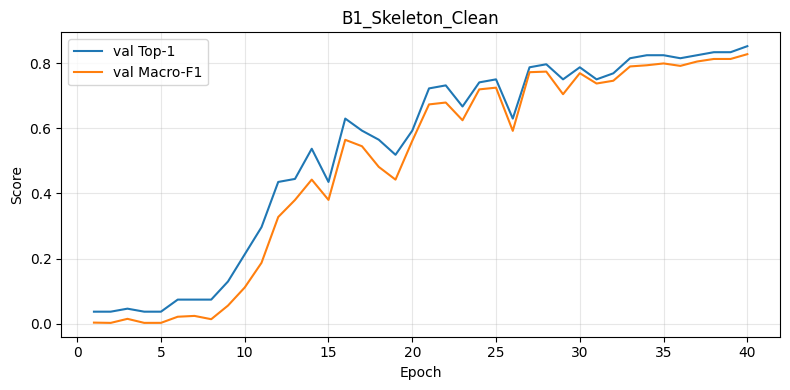


 B2_IMU_Clean
Epoch 001/40 | loss 3.0716 | val top1 6.48% | F1 3.82%
Epoch 002/40 | loss 1.4756 | val top1 21.30% | F1 15.97%
Epoch 003/40 | loss 0.8107 | val top1 47.22% | F1 39.86%
Epoch 004/40 | loss 0.4866 | val top1 60.19% | F1 53.69%
Epoch 005/40 | loss 0.3274 | val top1 70.37% | F1 67.48%
Epoch 006/40 | loss 0.2376 | val top1 77.78% | F1 74.20%
Epoch 007/40 | loss 0.1874 | val top1 81.48% | F1 78.16%
Epoch 008/40 | loss 0.1504 | val top1 79.63% | F1 76.47%
Epoch 009/40 | loss 0.1291 | val top1 82.41% | F1 79.51%
Epoch 010/40 | loss 0.1090 | val top1 84.26% | F1 81.97%
Epoch 011/40 | loss 0.0992 | val top1 82.41% | F1 79.40%
Epoch 012/40 | loss 0.0881 | val top1 79.63% | F1 77.05%
Epoch 013/40 | loss 0.0805 | val top1 77.78% | F1 75.26%
Epoch 014/40 | loss 0.0688 | val top1 76.85% | F1 74.79%
Epoch 015/40 | loss 0.0681 | val top1 75.93% | F1 73.06%
Epoch 016/40 | loss 0.0584 | val top1 75.00% | F1 72.32%
Epoch 017/40 | loss 0.0551 | val top1 77.78% | F1 76.09%
Epoch 018/40 | los

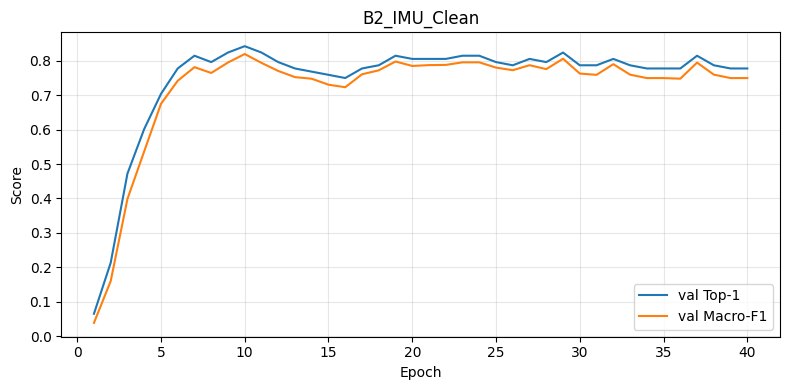


 B3_LateFusion_Clean
Epoch 001/40 | loss 3.0734 | val top1 3.70% | F1 0.26%
Epoch 002/40 | loss 2.3892 | val top1 3.70% | F1 0.26%
Epoch 003/40 | loss 1.8491 | val top1 11.11% | F1 4.90%
Epoch 004/40 | loss 1.4014 | val top1 16.67% | F1 9.42%
Epoch 005/40 | loss 1.0298 | val top1 26.85% | F1 20.47%
Epoch 006/40 | loss 0.7131 | val top1 34.26% | F1 27.66%
Epoch 007/40 | loss 0.4823 | val top1 47.22% | F1 39.36%
Epoch 008/40 | loss 0.3413 | val top1 53.70% | F1 46.32%
Epoch 009/40 | loss 0.2402 | val top1 66.67% | F1 58.90%
Epoch 010/40 | loss 0.1860 | val top1 79.63% | F1 74.10%
Epoch 011/40 | loss 0.1455 | val top1 89.81% | F1 88.51%
Epoch 012/40 | loss 0.1199 | val top1 92.59% | F1 91.21%
Epoch 013/40 | loss 0.0995 | val top1 93.52% | F1 92.06%
Epoch 014/40 | loss 0.0817 | val top1 89.81% | F1 88.19%
Epoch 015/40 | loss 0.0770 | val top1 90.74% | F1 89.14%
Epoch 016/40 | loss 0.0673 | val top1 95.37% | F1 94.12%
Epoch 017/40 | loss 0.0653 | val top1 94.44% | F1 93.09%
Epoch 018/40 | 

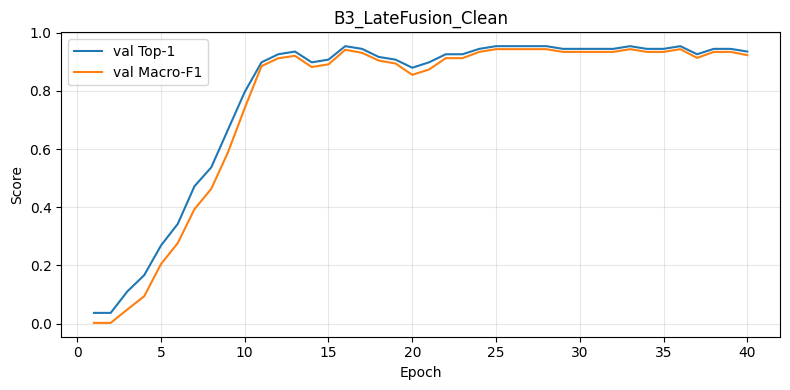


 B4_LateFusion_Robust
Epoch 001/40 | loss 5.1225 | val top1 3.70% | F1 0.26%
Epoch 002/40 | loss 4.1520 | val top1 14.81% | F1 7.46%
Epoch 003/40 | loss 3.2157 | val top1 35.19% | F1 23.82%
Epoch 004/40 | loss 2.4985 | val top1 55.56% | F1 47.39%
Epoch 005/40 | loss 1.9004 | val top1 73.15% | F1 70.70%
Epoch 006/40 | loss 1.3394 | val top1 89.81% | F1 88.25%
Epoch 007/40 | loss 0.9974 | val top1 88.89% | F1 86.36%
Epoch 008/40 | loss 0.7850 | val top1 93.52% | F1 91.83%
Epoch 009/40 | loss 0.6741 | val top1 89.81% | F1 88.57%
Epoch 010/40 | loss 0.4979 | val top1 91.67% | F1 89.85%
Epoch 011/40 | loss 0.4255 | val top1 93.52% | F1 91.83%
Epoch 012/40 | loss 0.3855 | val top1 92.59% | F1 90.89%
Epoch 013/40 | loss 0.3649 | val top1 90.74% | F1 89.42%
Epoch 014/40 | loss 0.3432 | val top1 86.11% | F1 83.94%
Epoch 015/40 | loss 0.2911 | val top1 90.74% | F1 89.14%
Epoch 016/40 | loss 0.3058 | val top1 88.89% | F1 86.95%
Epoch 017/40 | loss 0.2457 | val top1 92.59% | F1 91.35%
Epoch 018/4

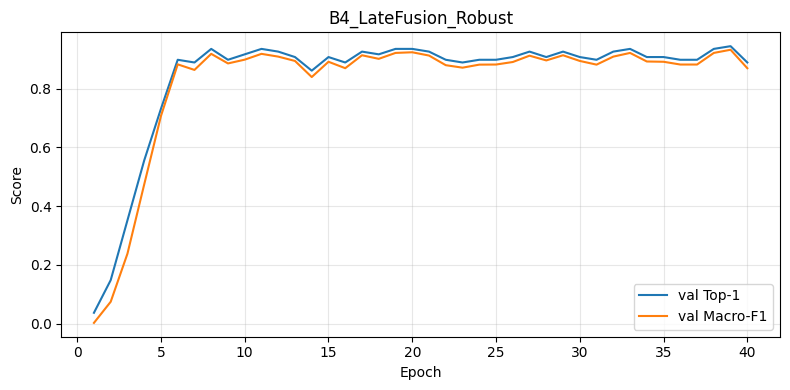


 P1_RATA_MAR_SI_v21


/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


Epoch 001/40 | loss 5.2882 | val top1 3.70% | F1 0.26%
Epoch 002/40 | loss 2.8538 | val top1 11.11% | F1 5.49%
Epoch 003/40 | loss 1.7524 | val top1 44.44% | F1 39.28%
Epoch 004/40 | loss 1.2947 | val top1 63.89% | F1 59.29%
Epoch 005/40 | loss 0.9764 | val top1 74.07% | F1 70.36%
Epoch 006/40 | loss 0.7753 | val top1 86.11% | F1 83.71%
Epoch 007/40 | loss 0.6919 | val top1 86.11% | F1 84.30%
Epoch 008/40 | loss 0.6329 | val top1 87.04% | F1 85.17%
Epoch 009/40 | loss 0.6068 | val top1 86.11% | F1 83.94%
Epoch 010/40 | loss 0.5322 | val top1 87.96% | F1 85.87%
Epoch 011/40 | loss 0.5075 | val top1 87.96% | F1 85.45%
Epoch 012/40 | loss 0.4922 | val top1 91.67% | F1 89.95%
Epoch 013/40 | loss 0.4522 | val top1 83.33% | F1 79.49%
Epoch 014/40 | loss 0.4674 | val top1 87.04% | F1 84.07%
Epoch 015/40 | loss 0.4213 | val top1 84.26% | F1 82.55%
Epoch 016/40 | loss 0.4125 | val top1 88.89% | F1 87.64%
Epoch 017/40 | loss 0.3920 | val top1 88.89% | F1 87.36%
Epoch 018/40 | loss 0.3549 | val t

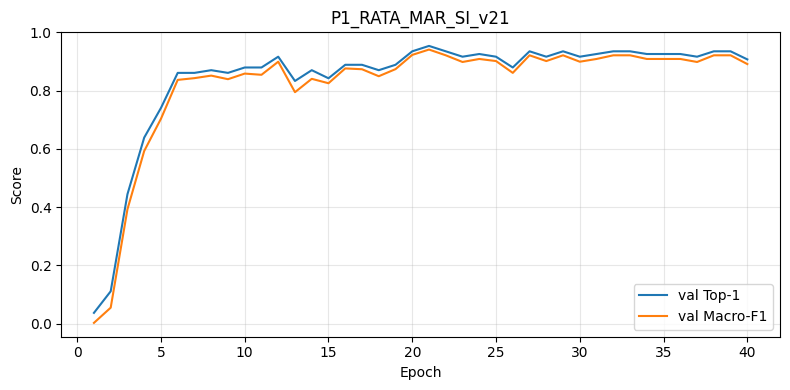

In [10]:
DEV_SPECS=[
    ('B1_Skeleton_Clean',SkeletonOnly,'clean'),
    ('B2_IMU_Clean',IMUOnly,'clean'),
    ('B3_LateFusion_Clean',LateFusionSI,'clean'),
    ('B4_LateFusion_Robust',LateFusionSI,'late_robust'),
    ('P1_RATA_MAR_SI_v21',RATAMAR_SI_v2,'rata_v2'),
]
DEV_HIST={}
for run_name,ctor,mode in DEV_SPECS:
    print('\n'+'='*80+'\n',run_name)
    seed_everything(DEV_SEED)
    model=ctor()
    loader=make_loader(tr_df,L_SK,L_IMU,batch=BATCH,shuffle=True,seed=DEV_SEED)
    hist=train_model(model,loader,val_loader,RUNS/run_name,epochs=DEV_EPOCHS,lr=LR,mode=mode,seed=DEV_SEED,force=FORCE_RETRAIN_DEV)
    DEV_HIST[run_name]=hist
    plot_history(hist,run_name,FIGS/f'dev_{run_name}_history.png')

## 11 — Load best development checkpoints

In [11]:
m_s=load_best(SkeletonOnly(),RUNS/'B1_Skeleton_Clean/best.pt')
m_i=load_best(IMUOnly(),RUNS/'B2_IMU_Clean/best.pt')
m_l_clean=load_best(LateFusionSI(),RUNS/'B3_LateFusion_Clean/best.pt')
m_l_robust=load_best(LateFusionSI(),RUNS/'B4_LateFusion_Robust/best.pt')
m_r=load_best(RATAMAR_SI_v2(),RUNS/'P1_RATA_MAR_SI_v21/best.pt')
print('Development checkpoints loaded.')

Development checkpoints loaded.


/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


## 12 — Clean validation comparison (NOT official test)

In [12]:
rows=[]
for name,model in [('SkeletonOnly',m_s),('IMUOnly',m_i),('LateFusion-Clean',m_l_clean),('LateFusion-Robust',m_l_robust),('RATA-MAR-SI-v2.1',m_r)]:
    r=evaluate(model,val_loader,'clean'); r['model']=name; rows.append(r)
dev_clean=pd.DataFrame(rows)
display(dev_clean[['model','top1','macro_f1']].sort_values('top1',ascending=False))
dev_clean.to_csv(TABLES/'DEV_clean_validation.csv',index=False)

,model,top1,macro_f1
2,LateFusion-Clean,0.953704,0.941211
4,RATA-MAR-SI-v2.1,0.953704,0.941211
3,LateFusion-Robust,0.944444,0.932257
0,SkeletonOnly,0.851852,0.827278
1,IMUOnly,0.842593,0.819742


## 13 — Paired deterministic robustness on validation subject 7

model,LateFusion-Clean,LateFusion-Robust,RATA-MAR-SI-v2.1
scenario,,,
clean,0.953704,0.944444,0.953704
imu_noise,0.944444,0.948148,0.942593
imu_noise_strong,0.868519,0.925926,0.920370
joint_drop_30,0.748148,0.938889,0.925926
joint_drop_50,0.359259,0.914815,0.896296
missing_imu,0.138889,0.481481,0.555556
missing_skeleton,0.037037,0.750000,0.824074
skeleton_noise,0.868519,0.937037,0.940741
skeleton_noise_strong,0.177778,0.796296,0.750000


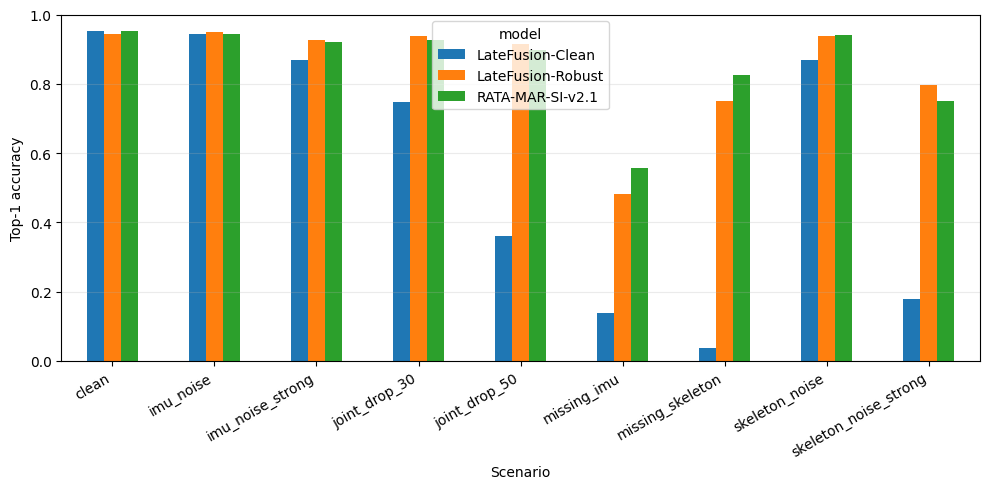

In [13]:
scenarios=['clean','missing_skeleton','missing_imu','skeleton_noise','skeleton_noise_strong','imu_noise','imu_noise_strong','joint_drop_30','joint_drop_50']
rows=[]; raw_repeat_rows=[]
for name,model in [('LateFusion-Clean',m_l_clean),('LateFusion-Robust',m_l_robust),('RATA-MAR-SI-v2.1',m_r)]:
    for sc in scenarios:
        if sc in STOCHASTIC_SCENARIOS:
            r,raw=evaluate_repeated_corruption(model,val_loader,sc,CORRUPTION_SEEDS)
            raw['model']=name; raw_repeat_rows.append(raw)
        else:
            r=evaluate(model,val_loader,sc)
            r['top1_corruption_std']=0.0; r['macro_f1_corruption_std']=0.0
        r['model']=name; rows.append(r)
dev_robust=pd.DataFrame(rows)
dev_robust_raw=pd.concat(raw_repeat_rows,ignore_index=True)
display(dev_robust.pivot(index='scenario',columns='model',values='top1'))
dev_robust.to_csv(TABLES/'DEV_robustness_paired.csv',index=False)
dev_robust_raw.to_csv(TABLES/'DEV_robustness_corruption_repeats.csv',index=False)
plot_robustness(dev_robust[['scenario','model','top1']],FIGS/'DEV_robustness.png')

## 14 — RATA reliability / adaptive fusion diagnostics on validation

In [14]:
diag_cols=['scenario','top1','macro_f1','mean_r_skel','mean_r_imu','mean_alpha_skel','mean_alpha_imu','aux_skel_acc','aux_imu_acc']
rata_diag=dev_robust[dev_robust.model=='RATA-MAR-SI-v2.1'][diag_cols].copy()
display(rata_diag)
rata_diag.to_csv(TABLES/'DEV_RATA_diagnostics.csv',index=False)

,scenario,top1,macro_f1,mean_r_skel,mean_r_imu,mean_alpha_skel,mean_alpha_imu,aux_skel_acc,aux_imu_acc
18,clean,0.953704,0.941211,0.457537,0.732417,0.334687,0.665313,0.601852,0.824074
19,missing_skeleton,0.824074,0.813198,0.107914,0.732417,0.063220,0.936780,0.037037,0.824074
20,missing_imu,0.555556,0.488839,0.457537,0.254560,0.674512,0.325488,0.601852,0.037037
21,skeleton_noise,0.940741,0.928042,0.417349,0.732417,0.306294,0.693706,0.427778,0.824074
22,skeleton_noise_strong,0.750000,0.723313,0.420775,0.732417,0.313641,0.686359,0.162963,0.824074
23,imu_noise,0.942593,0.929735,0.457537,0.748277,0.327211,0.672789,0.601852,0.774074
24,imu_noise_strong,0.920370,0.906437,0.457537,0.775160,0.315857,0.684143,0.601852,0.672222
25,joint_drop_30,0.925926,0.914345,0.369707,0.732417,0.271446,0.728554,0.390741,0.824074
26,joint_drop_50,0.896296,0.884666,0.265517,0.732417,0.190547,0.809453,0.224074,0.824074


## 15 — Temporal-delay robustness on validation

model,LateFusion-Clean,LateFusion-Robust,RATA-MAR-SI-v2.1
shift,,,
0,0.953704,0.944444,0.953704
4,0.949074,0.939815,0.953704
8,0.949074,0.949074,0.953704
16,0.898148,0.935185,0.944444


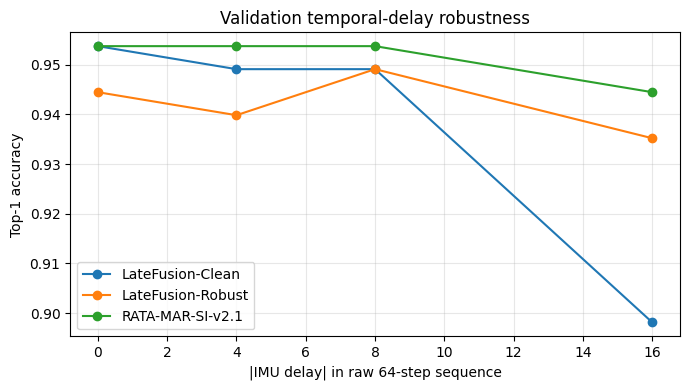

In [15]:
shift_rows=[]
for name,model in [('LateFusion-Clean',m_l_clean),('LateFusion-Robust',m_l_robust),('RATA-MAR-SI-v2.1',m_r)]:
    base=evaluate(model,val_loader,'clean')
    shift_rows.append({'model':name,'shift':0,'top1':base['top1'],'macro_f1':base['macro_f1']})
    for amount in [4,8,16]:
        r=evaluate_shift_average(model,val_loader,amount)
        shift_rows.append({'model':name,'shift':amount,'top1':r['top1'],'macro_f1':r['macro_f1']})
dev_shift=pd.DataFrame(shift_rows)
display(dev_shift.pivot(index='shift',columns='model',values='top1'))
dev_shift.to_csv(TABLES/'DEV_temporal_delay.csv',index=False)
plot_shift_curve(dev_shift,'Validation temporal-delay robustness',FIGS/'DEV_temporal_delay.png')

## 16 — Optional alignment heatmaps on validation (diagnostic only)

Sample: a1_s7_t1
Clean reliability: 0.414249062538147 0.7686566114425659
Clean alpha: [0.2877918481826782, 0.7122081518173218]


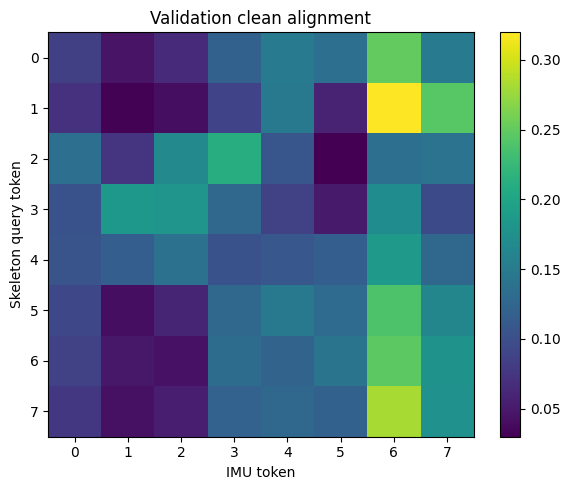

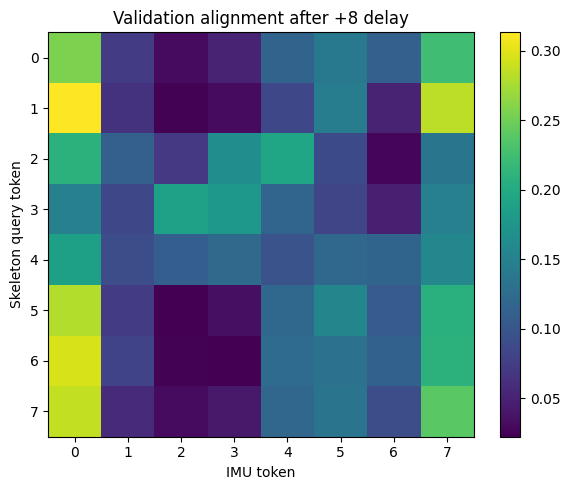

In [16]:
b=next(iter(val_loader)); xs=b['skeleton'][:1].cuda(); xi=b['imu'][:1].cuda(); m_r.eval()
with torch.no_grad():
    clean_out=m_r(xs,xi); delayed_out=m_r(xs,temporal_delay_zero_pad(xi,8))
print('Sample:',b['sample_id'][0])
print('Clean reliability:',float(clean_out['r_skel'].mean()),float(clean_out['r_imu'].mean()))
print('Clean alpha:',clean_out['alpha'].mean((0,1)).cpu().tolist())
plot_alignment(clean_out['align_skel_to_imu'][0].cpu().numpy(),'Validation clean alignment',FIGS/'DEV_alignment_clean.png')
plot_alignment(delayed_out['align_skel_to_imu'][0].cpu().numpy(),'Validation alignment after +8 delay',FIGS/'DEV_alignment_delay8.png')

## 17 — Development ablation: no alignment / no reliability

In [17]:
if RUN_DEVELOPMENT_ABLATION:
    ab_specs=[
        ('A1_NoAlignment',lambda: RATAMAR_SI_v2(use_alignment=False)),
        ('A2_NoReliability',lambda: RATAMAR_SI_v2(use_reliability=False)),
    ]
    ab_models={}
    for run_name,ctor in ab_specs:
        seed_everything(DEV_SEED); m=ctor(); loader=make_loader(tr_df,L_SK,L_IMU,batch=BATCH,shuffle=True,seed=DEV_SEED)
        train_model(m,loader,val_loader,RUNS/run_name,epochs=DEV_EPOCHS,lr=LR,mode='rata_v2',seed=DEV_SEED,force=FORCE_RETRAIN_DEV)
        seed_everything(DEV_SEED); ab_models[run_name]=load_best(ctor(),RUNS/run_name/'best.pt')

    ab_rows=[]
    for label,model in [('Full',m_r),('NoAlignment',ab_models['A1_NoAlignment']),('NoReliability',ab_models['A2_NoReliability'])]:
        for sc in ['clean','missing_skeleton','missing_imu','joint_drop_30','imu_noise']:
            if sc in STOCHASTIC_SCENARIOS:
                r,_=evaluate_repeated_corruption(model,val_loader,sc,CORRUPTION_SEEDS)
            else: r=evaluate(model,val_loader,sc)
            ab_rows.append({'variant':label,'scenario':sc,'top1':r['top1'],'macro_f1':r['macro_f1']})
        for amount in [4,8,16]:
            r=evaluate_shift_average(model,val_loader,amount)
            ab_rows.append({'variant':label,'scenario':f'delay_pm{amount}','top1':r['top1'],'macro_f1':r['macro_f1']})
    dev_ablation=pd.DataFrame(ab_rows)
    display(dev_ablation.pivot(index='scenario',columns='variant',values='top1'))
    dev_ablation.to_csv(TABLES/'DEV_ablation.csv',index=False)
else:
    print('Development ablation skipped.')

/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


Epoch 001/40 | loss 5.2180 | val top1 3.70% | F1 0.26%
Epoch 002/40 | loss 2.7992 | val top1 25.00% | F1 19.31%
Epoch 003/40 | loss 1.6776 | val top1 40.74% | F1 35.49%
Epoch 004/40 | loss 1.2412 | val top1 67.59% | F1 63.64%
Epoch 005/40 | loss 0.9516 | val top1 75.93% | F1 72.01%
Epoch 006/40 | loss 0.7613 | val top1 83.33% | F1 81.12%
Epoch 007/40 | loss 0.6722 | val top1 90.74% | F1 89.09%
Epoch 008/40 | loss 0.6306 | val top1 93.52% | F1 92.15%
Epoch 009/40 | loss 0.5823 | val top1 87.04% | F1 84.88%
Epoch 010/40 | loss 0.5038 | val top1 85.19% | F1 83.53%
Epoch 011/40 | loss 0.4906 | val top1 85.19% | F1 81.63%
Epoch 012/40 | loss 0.4731 | val top1 89.81% | F1 87.97%
Epoch 013/40 | loss 0.4415 | val top1 77.78% | F1 75.56%
Epoch 014/40 | loss 0.4683 | val top1 84.26% | F1 82.06%
Epoch 015/40 | loss 0.4021 | val top1 86.11% | F1 84.35%
Epoch 016/40 | loss 0.3830 | val top1 87.04% | F1 85.64%
Epoch 017/40 | loss 0.3890 | val top1 83.33% | F1 80.62%
Epoch 018/40 | loss 0.3509 | val 

/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


Epoch 001/40 | loss 5.3574 | val top1 3.70% | F1 0.26%
Epoch 002/40 | loss 3.0819 | val top1 6.48% | F1 4.22%
Epoch 003/40 | loss 1.9099 | val top1 23.15% | F1 20.01%
Epoch 004/40 | loss 1.4124 | val top1 46.30% | F1 39.57%
Epoch 005/40 | loss 1.0906 | val top1 75.93% | F1 71.89%
Epoch 006/40 | loss 0.8074 | val top1 78.70% | F1 74.99%
Epoch 007/40 | loss 0.7028 | val top1 90.74% | F1 89.14%
Epoch 008/40 | loss 0.6481 | val top1 93.52% | F1 92.29%
Epoch 009/40 | loss 0.5752 | val top1 92.59% | F1 91.38%
Epoch 010/40 | loss 0.5279 | val top1 87.96% | F1 86.28%
Epoch 011/40 | loss 0.4797 | val top1 85.19% | F1 81.89%
Epoch 012/40 | loss 0.4505 | val top1 94.44% | F1 93.18%
Epoch 013/40 | loss 0.4377 | val top1 87.04% | F1 84.83%
Epoch 014/40 | loss 0.4311 | val top1 90.74% | F1 88.60%
Epoch 015/40 | loss 0.3678 | val top1 89.81% | F1 88.20%
Epoch 016/40 | loss 0.3652 | val top1 90.74% | F1 89.01%
Epoch 017/40 | loss 0.3632 | val top1 92.59% | F1 91.11%
Epoch 018/40 | loss 0.3340 | val to

/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


variant,Full,NoAlignment,NoReliability
scenario,,,
clean,0.953704,0.944444,0.944444
delay_pm16,0.944444,0.916667,0.935185
delay_pm4,0.953704,0.939815,0.949074
delay_pm8,0.953704,0.935185,0.953704
imu_noise,0.942593,0.929630,0.946296
joint_drop_30,0.925926,0.924074,0.881481
missing_imu,0.555556,0.703704,0.462963
missing_skeleton,0.824074,0.870370,0.583333


## 18 — Development gate (validation evidence only)

In [18]:
clean_map=dict(zip(dev_clean.model,dev_clean.top1))
rata_map=dev_robust[dev_robust.model=='RATA-MAR-SI-v2.1'].set_index('scenario').top1.to_dict()
print('='*72); print('VALIDATION-ONLY DEVELOPMENT SUMMARY'); print('='*72)
for k,v in clean_map.items(): print(f'{k:22s}: {100*v:.2f}%')
for sc in ['missing_skeleton','missing_imu','joint_drop_30','imu_noise']:
    print(f'RATA {sc:17s}: {100*rata_map[sc]:.2f}%')
print('\nNo official test result has been inspected above this point.')
print('Architecture/hyperparameters are now considered FROZEN before final XSub.')

VALIDATION-ONLY DEVELOPMENT SUMMARY
SkeletonOnly          : 85.19%
IMUOnly               : 84.26%
LateFusion-Clean      : 95.37%
LateFusion-Robust     : 94.44%
RATA-MAR-SI-v2.1      : 95.37%
RATA missing_skeleton : 82.41%
RATA missing_imu      : 55.56%
RATA joint_drop_30    : 92.59%
RATA imu_noise        : 94.26%

No official test result has been inspected above this point.
Architecture/hyperparameters are now considered FROZEN before final XSub.


# FINAL OFFICIAL XSUB — use once after freezing the method
Train on subjects **1,3,5,7**, test on **2,4,6,8**. No test-based checkpoint selection.

## 19 — Final 3-seed training + locked official test

In [19]:
if RUN_FINAL:
    ftrain,ftest=official_train_test(MANIFEST)
    ftest_loader=make_loader(ftest,L_SK,L_IMU,batch=BATCH,shuffle=False,seed=0)
    final_specs=[
        ('SkeletonOnly',SkeletonOnly,'clean'),
        ('IMUOnly',IMUOnly,'clean'),
        ('LateFusion-Clean',LateFusionSI,'clean'),
        ('LateFusion-Robust',LateFusionSI,'late_robust'),
        ('RATA-MAR-SI-v2.1',RATAMAR_SI_v2,'rata_v2'),
    ]
    final_rows=[]; final_corr_raw=[]
    for seed in FINAL_SEEDS:
        for name,ctor,mode in final_specs:
            print('\n'+'='*84); print('FINAL | seed',seed,'|',name)
            safe=name.replace('/','_').replace(' ','_')
            ckpt=FINAL_MODELS/f'{safe}_seed{seed}.pt'
            seed_everything(seed)  # CRITICAL: BEFORE ctor()
            model=ctor()
            if ckpt.exists():
                print('Reuse:',ckpt); model=load_saved(model,ckpt)
            else:
                tr_loader=make_loader(ftrain,L_SK,L_IMU,batch=BATCH,shuffle=True,seed=seed)
                model=train_fixed(model,tr_loader,epochs=FINAL_EPOCHS,lr=LR,mode=mode,seed=seed)
                save_model(model,ckpt,{'seed':seed,'model':name,'epochs':FINAL_EPOCHS,'mode':mode})

            clean=evaluate(model,ftest_loader,'clean')
            row={'training_seed':seed,'model':name,'clean_top1':clean['top1'],'clean_macro_f1':clean['macro_f1']}
            if name in ['LateFusion-Clean','LateFusion-Robust','RATA-MAR-SI-v2.1']:
                for sc in ['missing_skeleton','missing_imu']:
                    rr=evaluate(model,ftest_loader,sc); row[sc]=rr['top1']
                for sc in ['skeleton_noise','imu_noise','joint_drop_30']:
                    rr,raw=evaluate_repeated_corruption(model,ftest_loader,sc,CORRUPTION_SEEDS)
                    row[sc]=rr['top1']; row[sc+'_corrstd']=rr['top1_corruption_std']
                    raw['training_seed']=seed; raw['model']=name; final_corr_raw.append(raw)
                for amount in [4,8,16]:
                    rr=evaluate_shift_average(model,ftest_loader,amount); row[f'delay_pm{amount}']=rr['top1']
            final_rows.append(row)
            del model; torch.cuda.empty_cache()

    final_df=pd.DataFrame(final_rows)
    final_df.to_csv(TABLES/'FINAL_XSUB_per_seed.csv',index=False)
    if final_corr_raw:
        pd.concat(final_corr_raw,ignore_index=True).to_csv(TABLES/'FINAL_XSUB_corruption_repeats.csv',index=False)
    display(final_df)

    metric_cols=[c for c in final_df.columns if c not in ['training_seed','model']]
    summary=final_df.groupby('model')[metric_cols].agg(['mean','std'])
    summary.to_csv(TABLES/'FINAL_XSUB_mean_std.csv')
    display(summary)
else:
    print('RUN_FINAL=False')


FINAL | seed 0 | SkeletonOnly
seed 0 | epoch 1/100
seed 0 | epoch 20/100
seed 0 | epoch 40/100
seed 0 | epoch 60/100
seed 0 | epoch 80/100
seed 0 | epoch 100/100

FINAL | seed 0 | IMUOnly
seed 0 | epoch 1/100
seed 0 | epoch 20/100
seed 0 | epoch 40/100
seed 0 | epoch 60/100
seed 0 | epoch 80/100
seed 0 | epoch 100/100

FINAL | seed 0 | LateFusion-Clean
seed 0 | epoch 1/100
seed 0 | epoch 20/100
seed 0 | epoch 40/100
seed 0 | epoch 60/100
seed 0 | epoch 80/100
seed 0 | epoch 100/100

FINAL | seed 0 | LateFusion-Robust
seed 0 | epoch 1/100
seed 0 | epoch 20/100
seed 0 | epoch 40/100
seed 0 | epoch 60/100
seed 0 | epoch 80/100
seed 0 | epoch 100/100

FINAL | seed 0 | RATA-MAR-SI-v2.1


/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


seed 0 | epoch 1/100
seed 0 | epoch 20/100
seed 0 | epoch 40/100
seed 0 | epoch 60/100
seed 0 | epoch 80/100
seed 0 | epoch 100/100

FINAL | seed 1 | SkeletonOnly
seed 1 | epoch 1/100
seed 1 | epoch 20/100
seed 1 | epoch 40/100
seed 1 | epoch 60/100
seed 1 | epoch 80/100
seed 1 | epoch 100/100

FINAL | seed 1 | IMUOnly
seed 1 | epoch 1/100
seed 1 | epoch 20/100
seed 1 | epoch 40/100
seed 1 | epoch 60/100
seed 1 | epoch 80/100
seed 1 | epoch 100/100

FINAL | seed 1 | LateFusion-Clean
seed 1 | epoch 1/100
seed 1 | epoch 20/100
seed 1 | epoch 40/100
seed 1 | epoch 60/100
seed 1 | epoch 80/100
seed 1 | epoch 100/100

FINAL | seed 1 | LateFusion-Robust
seed 1 | epoch 1/100
seed 1 | epoch 20/100
seed 1 | epoch 40/100
seed 1 | epoch 60/100
seed 1 | epoch 80/100
seed 1 | epoch 100/100

FINAL | seed 1 | RATA-MAR-SI-v2.1


/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


seed 1 | epoch 1/100
seed 1 | epoch 20/100
seed 1 | epoch 40/100
seed 1 | epoch 60/100
seed 1 | epoch 80/100
seed 1 | epoch 100/100

FINAL | seed 2 | SkeletonOnly
seed 2 | epoch 1/100
seed 2 | epoch 20/100
seed 2 | epoch 40/100
seed 2 | epoch 60/100
seed 2 | epoch 80/100
seed 2 | epoch 100/100

FINAL | seed 2 | IMUOnly
seed 2 | epoch 1/100
seed 2 | epoch 20/100
seed 2 | epoch 40/100
seed 2 | epoch 60/100
seed 2 | epoch 80/100
seed 2 | epoch 100/100

FINAL | seed 2 | LateFusion-Clean
seed 2 | epoch 1/100
seed 2 | epoch 20/100
seed 2 | epoch 40/100
seed 2 | epoch 60/100
seed 2 | epoch 80/100
seed 2 | epoch 100/100

FINAL | seed 2 | LateFusion-Robust
seed 2 | epoch 1/100
seed 2 | epoch 20/100
seed 2 | epoch 40/100
seed 2 | epoch 60/100
seed 2 | epoch 80/100
seed 2 | epoch 100/100

FINAL | seed 2 | RATA-MAR-SI-v2.1


/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


seed 2 | epoch 1/100
seed 2 | epoch 20/100
seed 2 | epoch 40/100
seed 2 | epoch 60/100
seed 2 | epoch 80/100
seed 2 | epoch 100/100


,training_seed,model,clean_top1,clean_macro_f1,missing_skeleton,missing_imu,skeleton_noise,skeleton_noise_corrstd,imu_noise,imu_noise_corrstd,joint_drop_30,joint_drop_30_corrstd,delay_pm4,delay_pm8,delay_pm16
0,0,SkeletonOnly,0.841860,0.837650,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,IMUOnly,0.874419,0.867084,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0,LateFusion-Clean,0.934884,0.932902,0.037209,0.093023,0.817209,0.003120,0.929302,0.004822,0.679070,0.020473,0.932558,0.927907,0.904651
3,0,LateFusion-Robust,0.948837,0.948530,0.860465,0.583721,0.929767,0.001946,0.946512,0.004651,0.933023,0.007607,0.941860,0.938372,0.929070
4,0,RATA-MAR-SI-v2.1,0.941860,0.940833,0.872093,0.816279,0.928837,0.003527,0.940000,0.003821,0.918140,0.004473,0.936047,0.938372,0.925581
5,1,SkeletonOnly,0.806977,0.798158,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1,IMUOnly,0.888372,0.878714,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,1,LateFusion-Clean,0.939535,0.938942,0.037209,0.072093,0.887442,0.005837,0.939070,0.005042,0.797209,0.009360,0.940698,0.941860,0.923256
8,1,LateFusion-Robust,0.934884,0.933363,0.844186,0.595349,0.924186,0.004822,0.938140,0.006899,0.924651,0.005601,0.937209,0.938372,0.923256
9,1,RATA-MAR-SI-v2.1,0.951163,0.951259,0.879070,0.797674,0.934884,0.003289,0.953953,0.002548,0.932558,0.004351,0.950000,0.946512,0.937209


clean_top1           clean_macro_f1            \
                        mean       std           mean       std   
model                                                             
IMUOnly             0.877519  0.009682       0.869206  0.008645   
LateFusion-Clean    0.933333  0.007105       0.932162  0.007178   
LateFusion-Robust   0.935659  0.012808       0.934489  0.013513   
RATA-MAR-SI-v2.1    0.950388  0.008167       0.950089  0.008730   
SkeletonOnly        0.833333  0.023295       0.829094  0.027669   

                  missing_skeleton           missing_imu            \
                              mean       std        mean       std   
model                                                                
IMUOnly                        NaN       NaN         NaN       NaN   
LateFusion-Clean          0.037209  0.000000    0.090698  0.017558   
LateFusion-Robust         0.854264  0.008805    0.589147  0.005853   
RATA-MAR-SI-v2.1          0.879070  0.006977    0.804651  0.010137   
SkeletonOnly                   NaN       NaN         NaN       NaN   

                  skeleton_noise            ... joint_drop_30            \
                            mean       std  ...          mean       std   
model                                       ...                           
IMUOnly                      NaN       NaN  ...           NaN       NaN   
LateFusion-Clean        0.804341  0.090226  ...      0.759225  0.069448   
LateFusion-Robust       0.920930  0.010838  ...      0.927287  0.004973   
RATA-MAR-SI-v2.1        0.939070  0.012848  ...      0.932868  0.014886   
SkeletonOnly                 NaN       NaN  ...           NaN       NaN   

                  joint_drop_30_corrstd           delay_pm4            \
                                   mean       std      mean       std   
model                                                                   
IMUOnly                             NaN       NaN       NaN       NaN   
LateFusion-Clean               0.012663  0.006790  0.931783  0.009327   
LateFusion-Robust              0.005811  0.001701  0.934496  0.009032   
RATA-MAR-SI-v2.1               0.005036  0.001082  0.948450  0.011705   
SkeletonOnly                        NaN       NaN       NaN       NaN   

                  delay_pm8           delay_pm16            
                       mean       std       mean       std  
model                                                       
IMUOnly                 NaN       NaN        NaN       NaN  
LateFusion-Clean   0.929070  0.012251   0.910853  0.010741  
LateFusion-Robust  0.932558  0.010070   0.921318  0.008881  
RATA-MAR-SI-v2.1   0.947674  0.009935   0.937597  0.012214  
SkeletonOnly            NaN       NaN        NaN       NaN  

[5 rows x 26 columns]

## 20 — Final paper tables: clean and robustness summaries

In [20]:
assert (TABLES/'FINAL_XSUB_per_seed.csv').exists(), 'Run Cell 19 first.'
final_df=pd.read_csv(TABLES/'FINAL_XSUB_per_seed.csv')
clean_table=(final_df.groupby('model')[['clean_top1','clean_macro_f1']].agg(['mean','std']))
display(clean_table); clean_table.to_csv(TABLES/'PAPER_Table_Clean.csv')

fusion=final_df[final_df.model.isin(['LateFusion-Clean','LateFusion-Robust','RATA-MAR-SI-v2.1'])].copy()
rob_cols=['missing_skeleton','missing_imu','skeleton_noise','imu_noise','joint_drop_30','delay_pm4','delay_pm8','delay_pm16']
rob_table=fusion.groupby('model')[rob_cols].agg(['mean','std'])
display(rob_table); rob_table.to_csv(TABLES/'PAPER_Table_Robustness.csv')

clean_top1           clean_macro_f1          
                        mean       std           mean       std
model                                                          
IMUOnly             0.877519  0.009682       0.869206  0.008645
LateFusion-Clean    0.933333  0.007105       0.932162  0.007178
LateFusion-Robust   0.935659  0.012808       0.934489  0.013513
RATA-MAR-SI-v2.1    0.950388  0.008167       0.950089  0.008730
SkeletonOnly        0.833333  0.023295       0.829094  0.027669

missing_skeleton           missing_imu            \
                              mean       std        mean       std   
model                                                                
LateFusion-Clean          0.037209  0.000000    0.090698  0.017558   
LateFusion-Robust         0.854264  0.008805    0.589147  0.005853   
RATA-MAR-SI-v2.1          0.879070  0.006977    0.804651  0.010137   

                  skeleton_noise           imu_noise           joint_drop_30  \
                            mean       std      mean       std          mean   
model                                                                          
LateFusion-Clean        0.804341  0.090226  0.929612  0.009306      0.759225   
LateFusion-Robust       0.920930  0.010838  0.935349  0.012789      0.927287   
RATA-MAR-SI-v2.1        0.939070  0.012848  0.952713  0.012141      0.932868   

                            delay_pm4           delay_pm8            \
                        std      mean       std      mean       std   
model                                                                 
LateFusion-Clean   0.069448  0.931783  0.009327  0.929070  0.012251   
LateFusion-Robust  0.004973  0.934496  0.009032  0.932558  0.010070   
RATA-MAR-SI-v2.1   0.014886  0.948450  0.011705  0.947674  0.009935   

                  delay_pm16            
                        mean       std  
model                                   
LateFusion-Clean    0.910853  0.010741  
LateFusion-Robust   0.921318  0.008881  
RATA-MAR-SI-v2.1    0.937597  0.012214

## 21 — Final 3-seed ablation on locked test (Full vs NoAlignment vs NoReliability)

In [21]:
if RUN_FINAL_ABLATION:
    ftrain,ftest=official_train_test(MANIFEST)
    ftest_loader=make_loader(ftest,L_SK,L_IMU,batch=BATCH,shuffle=False,seed=0)
    ab_specs=[
        ('NoAlignment',lambda: RATAMAR_SI_v2(use_alignment=False)),
        ('NoReliability',lambda: RATAMAR_SI_v2(use_reliability=False)),
    ]
    ab_rows=[]
    # Reuse Full RATA rows already obtained.
    full=final_df[final_df.model=='RATA-MAR-SI-v2.1']
    for _,r in full.iterrows():
        ab_rows.append({'training_seed':int(r.training_seed),'variant':'Full',**{c:r[c] for c in ['clean_top1','missing_skeleton','missing_imu','joint_drop_30','imu_noise','delay_pm4','delay_pm8','delay_pm16']}})

    for seed in FINAL_SEEDS:
        for variant,ctor in ab_specs:
            print('\nFINAL ABLATION |',variant,'| seed',seed)
            ckpt=FINAL_MODELS/f'Ablation_{variant}_seed{seed}.pt'
            seed_everything(seed); model=ctor()
            if ckpt.exists(): model=load_saved(model,ckpt)
            else:
                tr_loader=make_loader(ftrain,L_SK,L_IMU,batch=BATCH,shuffle=True,seed=seed)
                model=train_fixed(model,tr_loader,epochs=FINAL_EPOCHS,lr=LR,mode='rata_v2',seed=seed)
                save_model(model,ckpt,{'seed':seed,'variant':variant,'epochs':FINAL_EPOCHS})
            row={'training_seed':seed,'variant':variant}
            row['clean_top1']=evaluate(model,ftest_loader,'clean')['top1']
            row['missing_skeleton']=evaluate(model,ftest_loader,'missing_skeleton')['top1']
            row['missing_imu']=evaluate(model,ftest_loader,'missing_imu')['top1']
            for sc in ['joint_drop_30','imu_noise']:
                rr,_=evaluate_repeated_corruption(model,ftest_loader,sc,CORRUPTION_SEEDS); row[sc]=rr['top1']
            for a in [4,8,16]: row[f'delay_pm{a}']=evaluate_shift_average(model,ftest_loader,a)['top1']
            ab_rows.append(row); del model; torch.cuda.empty_cache()

    final_ab=pd.DataFrame(ab_rows); final_ab.to_csv(TABLES/'FINAL_Ablation_per_seed.csv',index=False)
    ab_summary=final_ab.groupby('variant').agg(['mean','std']); ab_summary.to_csv(TABLES/'PAPER_Table_Ablation.csv')
    display(ab_summary)
else:
    print('Final ablation skipped.')


FINAL ABLATION | NoAlignment | seed 0


/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


seed 0 | epoch 1/100
seed 0 | epoch 20/100
seed 0 | epoch 40/100
seed 0 | epoch 60/100
seed 0 | epoch 80/100
seed 0 | epoch 100/100

FINAL ABLATION | NoReliability | seed 0


/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


seed 0 | epoch 1/100
seed 0 | epoch 20/100
seed 0 | epoch 40/100
seed 0 | epoch 60/100
seed 0 | epoch 80/100
seed 0 | epoch 100/100

FINAL ABLATION | NoAlignment | seed 1


/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


... (4 outputs left out)

seed 2 | epoch 1/100
seed 2 | epoch 20/100
seed 2 | epoch 40/100
seed 2 | epoch 60/100
seed 2 | epoch 80/100
seed 2 | epoch 100/100

FINAL ABLATION | NoReliability | seed 2


/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


seed 2 | epoch 1/100
seed 2 | epoch 20/100
seed 2 | epoch 40/100
seed 2 | epoch 60/100
seed 2 | epoch 80/100
seed 2 | epoch 100/100


training_seed      clean_top1           missing_skeleton  \
                       mean  std       mean       std             mean   
variant                                                                  
Full                    1.0  1.0   0.950388  0.008167         0.879070   
NoAlignment             1.0  1.0   0.948062  0.004841         0.871318   
NoReliability           1.0  1.0   0.945736  0.013427         0.878295   

                        missing_imu           joint_drop_30            \
                    std        mean       std          mean       std   
variant                                                                 
Full           0.006977    0.804651  0.010137      0.932868  0.014886   
NoAlignment    0.014210    0.803101  0.024205      0.929612  0.008530   
NoReliability  0.007476    0.820155  0.015484      0.930853  0.010247   

              imu_noise           delay_pm4           delay_pm8            \
                   mean       std      mean       std      mean       std   
variant                                                                     
Full           0.952713  0.012141  0.948450  0.011705  0.947674  0.009935   
NoAlignment    0.947287  0.004010  0.951938  0.004699  0.946124  0.002926   
NoReliability  0.945891  0.010741  0.938760  0.007566  0.939535  0.010657   

              delay_pm16            
                    mean       std  
variant                             
Full            0.937597  0.012214  
NoAlignment     0.936047  0.006474  
NoReliability   0.934496  0.001343

## 22 — Final RATA seed-0 confusion matrix + per-class report (pre-specified representative seed)

/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


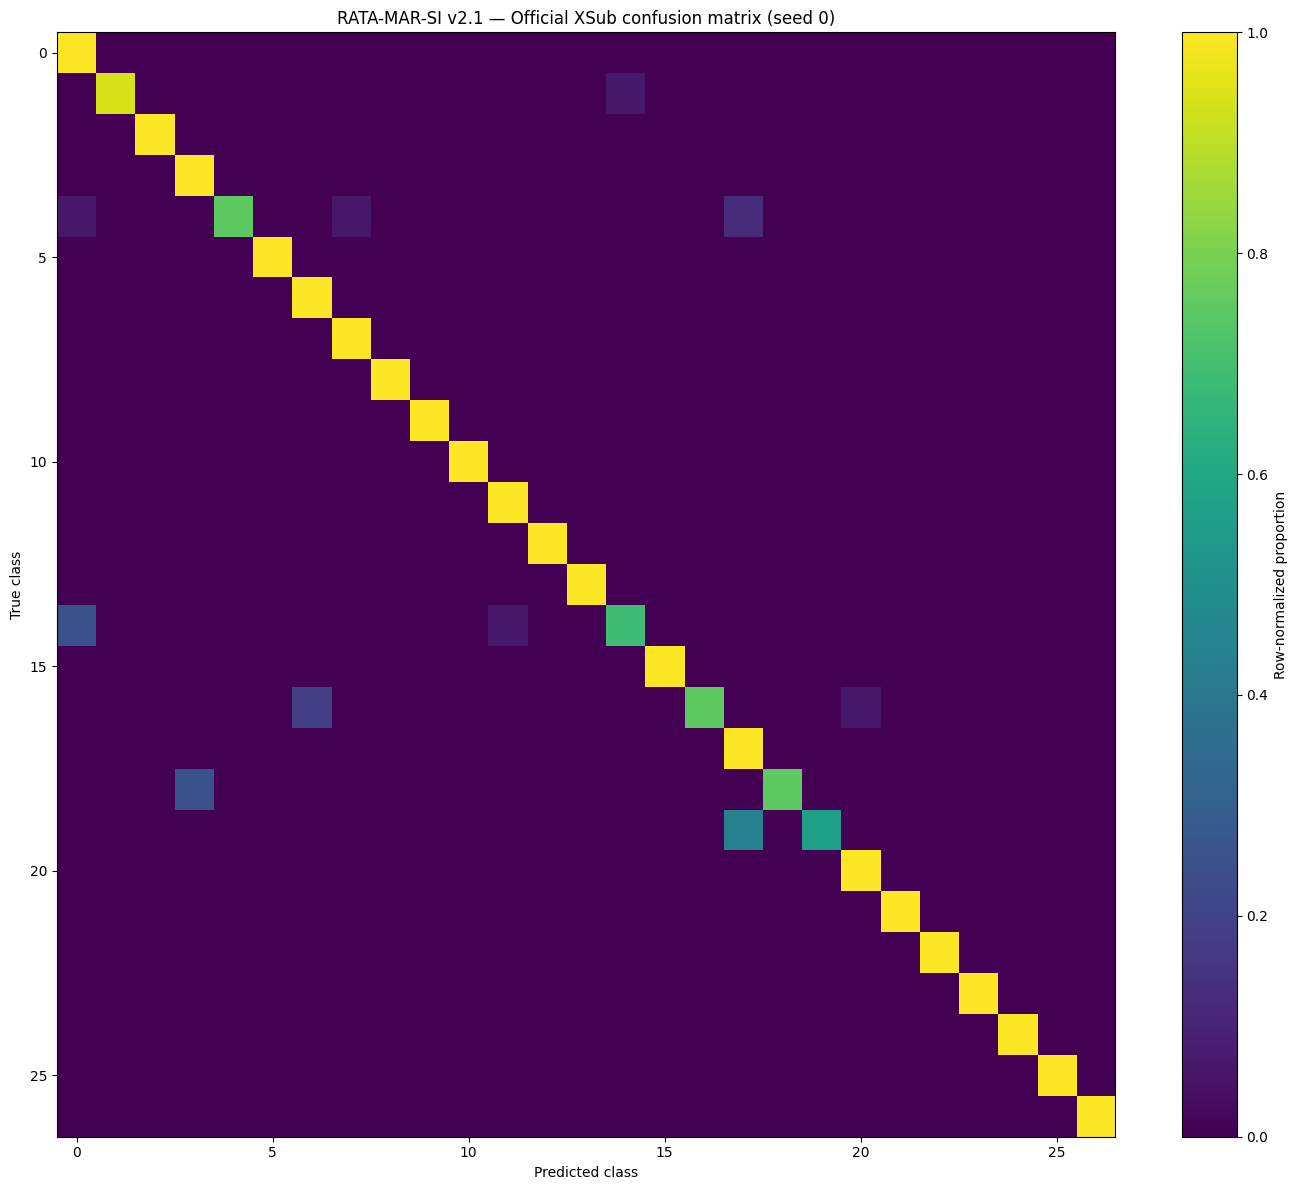

,precision,recall,f1-score,support
right_hand_catch_object,1.000000,0.5625,0.720000,16.0
two_hand_push,0.640000,1.0000,0.780488,16.0
tennis_right_forehand,0.916667,0.6875,0.785714,16.0
right_arm_throw,1.000000,0.7500,0.857143,16.0
right_hand_knock_door,1.000000,0.7500,0.857143,16.0
tennis_serve,1.000000,0.7500,0.857143,16.0
right_arm_swipe_left,0.761905,1.0000,0.864865,16.0
two_hand_front_clap,0.800000,1.0000,0.888889,16.0
basketball_shoot,0.842105,1.0000,0.914286,16.0
right_arm_swipe_right,1.000000,0.9375,0.967742,16.0


In [22]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

ftrain,ftest=official_train_test(MANIFEST)
ftest_loader=make_loader(ftest,L_SK,L_IMU,batch=BATCH,shuffle=False,seed=0)
seed_everything(0)
rata0=load_saved(RATAMAR_SI_v2(),FINAL_MODELS/'RATA-MAR-SI-v2.1_seed0.pt')
pred=evaluate(rata0,ftest_loader,'clean',return_predictions=True)
pred_df=pd.DataFrame({'sample_id':pred['sample_id'],'y_true':pred['y_true'],'y_pred':pred['y_pred']})
pred_df.to_csv(TABLES/'FINAL_RATA_seed0_predictions.csv',index=False)

label_map=(manifest[['label','action_name']].drop_duplicates().sort_values('label'))
labels=label_map.label.tolist(); names=label_map.action_name.tolist()
cm=confusion_matrix(pred['y_true'],pred['y_pred'],labels=labels)
pd.DataFrame(cm,index=names,columns=names).to_csv(TABLES/'FINAL_RATA_seed0_confusion_raw.csv')
cmn=cm/np.clip(cm.sum(axis=1,keepdims=True),1,None)
plt.figure(figsize=(14,12)); plt.imshow(cmn,aspect='auto',vmin=0,vmax=1); plt.colorbar(label='Row-normalized proportion')
plt.xlabel('Predicted class'); plt.ylabel('True class'); plt.title('RATA-MAR-SI v2.1 — Official XSub confusion matrix (seed 0)')
plt.tight_layout(); plt.savefig(FIGS/'FINAL_confusion_matrix_seed0.png',dpi=300,bbox_inches='tight'); plt.show()

report=classification_report(pred['y_true'],pred['y_pred'],labels=labels,target_names=names,output_dict=True,zero_division=0)
per_class=pd.DataFrame(report).T
per_class.to_csv(TABLES/'FINAL_RATA_seed0_per_class.csv')
display(per_class.iloc[:27].sort_values('f1-score').head(10))

## 23 — Final RATA reliability/fusion diagnostics on official test

In [23]:
diag_rows=[]
for sc in ['clean','missing_skeleton','missing_imu','skeleton_noise','imu_noise','joint_drop_30']:
    if sc in STOCHASTIC_SCENARIOS:
        r,_=evaluate_repeated_corruption(rata0,ftest_loader,sc,CORRUPTION_SEEDS)
    else: r=evaluate(rata0,ftest_loader,sc)
    diag_rows.append(r)
final_diag=pd.DataFrame(diag_rows)
cols=[c for c in ['scenario','top1','macro_f1','mean_r_skel','mean_r_imu','mean_alpha_skel','mean_alpha_imu','aux_skel_acc','aux_imu_acc'] if c in final_diag.columns]
display(final_diag[cols]); final_diag[cols].to_csv(TABLES/'FINAL_RATA_seed0_diagnostics.csv',index=False)

,scenario,top1,macro_f1,mean_r_skel,mean_r_imu,mean_alpha_skel,mean_alpha_imu,aux_skel_acc,aux_imu_acc
0,clean,0.941860,0.940833,0.861274,0.913220,0.479441,0.520559,0.748837,0.872093
1,missing_skeleton,0.872093,0.866338,0.076737,0.913220,0.029389,0.970611,0.037209,0.872093
2,missing_imu,0.816279,0.811684,0.861274,0.277333,0.833893,0.166107,0.748837,0.037209
3,skeleton_noise,0.928837,0.927575,0.806042,0.913220,0.455752,0.544248,0.712093,0.872093
4,imu_noise,0.940000,0.938866,0.861274,0.923412,0.475156,0.524844,0.748837,0.862326
5,joint_drop_30,0.918140,0.916604,0.732248,0.913220,0.418847,0.581153,0.559535,0.872093


## 24 — Efficiency: parameters, model size, FLOPs (if supported), latency, FPS, peak GPU memory

In [24]:
if RUN_EFFICIENCY:
    import io, time, numpy as np
    from thop import profile
    import torch.nn as nn

    class LogitWrapper(nn.Module):
        def __init__(self,m): super().__init__(); self.m=m
        def forward(self,sk,imu): return self.m(sk,imu)['logits']

    specs=[('SkeletonOnly',SkeletonOnly),('IMUOnly',IMUOnly),('LateFusion-Clean',LateFusionSI),('LateFusion-Robust',LateFusionSI),('RATA-MAR-SI-v2.1',RATAMAR_SI_v2)]
    eff=[]
    for name,ctor in specs:
        seed_everything(0); model=load_saved(ctor(),FINAL_MODELS/f"{name.replace(' ','_')}_seed0.pt").eval()
        params=sum(p.numel() for p in model.parameters())
        buf=io.BytesIO(); torch.save(model.state_dict(),buf); size_mb=len(buf.getvalue())/1024**2
        sk1=torch.randn(1,64,20,3,device='cuda'); im1=torch.randn(1,64,6,device='cuda')
        try:
            macs,_=profile(LogitWrapper(model).cuda(),inputs=(sk1,im1),verbose=False); gmacs=macs/1e9
        except Exception as e:
            print('THOP failed for',name,repr(e)); gmacs=np.nan
        for _ in range(30): model(sk1,im1)
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        times=[]
        for _ in range(100):
            st=torch.cuda.Event(enable_timing=True); en=torch.cuda.Event(enable_timing=True)
            st.record(); model(sk1,im1); en.record(); torch.cuda.synchronize(); times.append(st.elapsed_time(en))
        peak_mb=torch.cuda.max_memory_allocated()/1024**2
        mean_ms=float(np.mean(times)); p95_ms=float(np.percentile(times,95)); fps=1000.0/mean_ms
        eff.append({'model':name,'params_M':params/1e6,'state_dict_MB':size_mb,'GMACs_THOP':gmacs,'latency_ms_mean_b1':mean_ms,'latency_ms_p95_b1':p95_ms,'FPS_b1':fps,'peak_GPU_MB':peak_mb})
        del model,sk1,im1; torch.cuda.empty_cache()
    eff_df=pd.DataFrame(eff); display(eff_df); eff_df.to_csv(TABLES/'PAPER_Table_Efficiency.csv',index=False)
else: print('Efficiency profiling skipped.')

/content/drive/MyDrive/RATA_IASC/src_rata_mar_si_v21/models_v21.py:276: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal = nn.TransformerEncoder(layer, num_layers=transformer_layers)


,model,params_M,state_dict_MB,GMACs_THOP,latency_ms_mean_b1,latency_ms_p95_b1,FPS_b1,peak_GPU_MB
0,SkeletonOnly,0.521627,2.015954,0.660447,2.347428,2.437786,425.998186,627.260254
1,IMUOnly,0.150299,0.583650,0.009208,0.911688,0.944230,1096.866853,99.045410
2,LateFusion-Clean,0.796315,3.073392,0.669779,3.278899,3.389696,304.980403,630.901855
3,LateFusion-Robust,0.796315,3.073392,0.669779,3.689943,4.245555,271.006894,628.313965
4,RATA-MAR-SI-v2.1,2.985435,11.443549,0.679696,8.576379,9.815552,116.599326,636.730957


## 25 — Publication-ready final figures from mean results

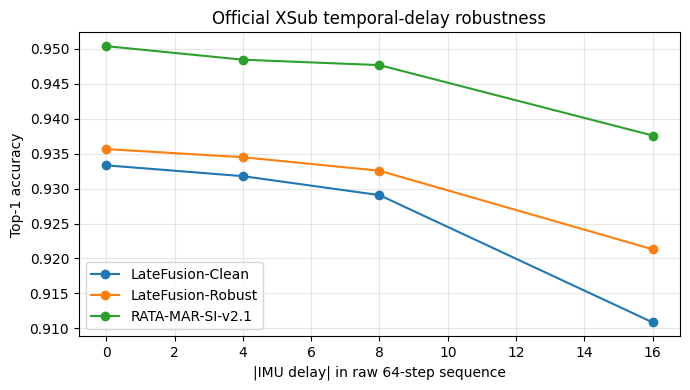

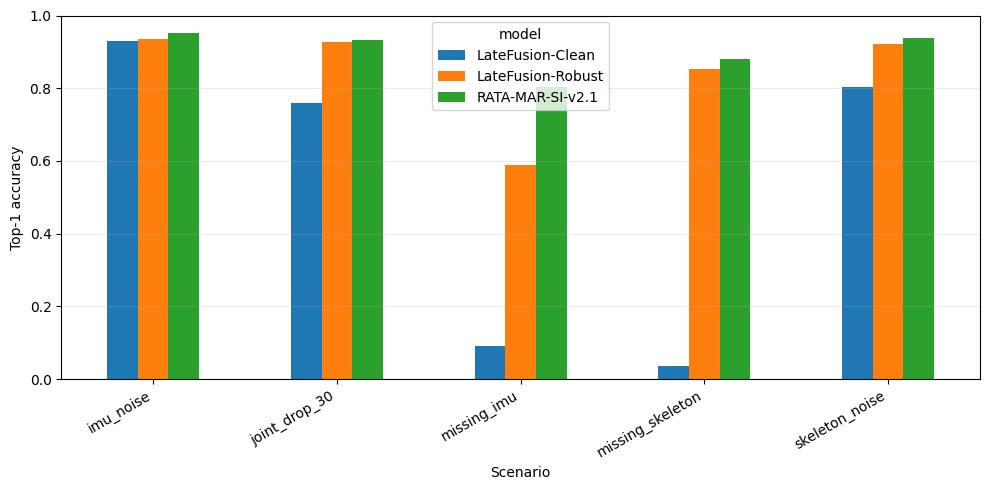

In [25]:
import matplotlib.pyplot as plt
fusion=final_df[final_df.model.isin(['LateFusion-Clean','LateFusion-Robust','RATA-MAR-SI-v2.1'])].copy()
# Delay curve: mean across training seeds.
delay_rows=[]
for model,g in fusion.groupby('model'):
    delay_rows.append({'model':model,'shift':0,'top1':g.clean_top1.mean()})
    for a in [4,8,16]: delay_rows.append({'model':model,'shift':a,'top1':g[f'delay_pm{a}'].mean()})
final_shift_plot=pd.DataFrame(delay_rows)
plot_shift_curve(final_shift_plot,'Official XSub temporal-delay robustness',FIGS/'PAPER_Fig_temporal_delay.png')
final_shift_plot.to_csv(TABLES/'PAPER_Fig_temporal_delay_data.csv',index=False)

# Robustness bar from mean training-seed results.
rob_scen=['missing_skeleton','missing_imu','skeleton_noise','imu_noise','joint_drop_30']
rows=[]
for model,g in fusion.groupby('model'):
    for sc in rob_scen: rows.append({'model':model,'scenario':sc,'top1':g[sc].mean()})
final_rob_plot=pd.DataFrame(rows)
plot_robustness(final_rob_plot,FIGS/'PAPER_Fig_robustness.png')
final_rob_plot.to_csv(TABLES/'PAPER_Fig_robustness_data.csv',index=False)

## 26 — Save run manifest for reproducibility

In [26]:
run_manifest={
    'method':'RATA-MAR-SI v2.1',
    'architecture_change_vs_v2':False,
    'dataset':'Original UTD-MHAD Skeleton + Inertial',
    'n_sequences':861,'n_actions':27,
    'development_train_subjects':[1,3,5],'development_val_subject':[7],
    'official_train_subjects':[1,3,5,7],'official_test_subjects':[2,4,6,8],
    'dev_epochs':DEV_EPOCHS,'final_epochs':FINAL_EPOCHS,'lr':LR,'batch':BATCH,
    'final_seeds':FINAL_SEEDS,'corruption_seeds':CORRUPTION_SEEDS,
    'torch':torch.__version__,'cuda':torch.version.cuda,'gpu':torch.cuda.get_device_name(0),
}
(RUNS/'run_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
print(json.dumps(run_manifest,indent=2))

{
  "method": "RATA-MAR-SI v2.1",
  "architecture_change_vs_v2": false,
  "dataset": "Original UTD-MHAD Skeleton + Inertial",
  "n_sequences": 861,
  "n_actions": 27,
  "development_train_subjects": [
    1,
    3,
    5
  ],
  "development_val_subject": [
    7
  ],
  "official_train_subjects": [
    1,
    3,
    5,
    7
  ],
  "official_test_subjects": [
    2,
    4,
    6,
    8
  ],
  "dev_epochs": 40,
  "final_epochs": 100,
  "lr": 0.0003,
  "batch": 64,
  "final_seeds": [
    0,
    1,
    2
  ],
  "corruption_seeds": [
    1103,
    2207,
    3301,
    4409,
    5519
  ],
  "torch": "2.11.0+cu128",
  "cuda": "12.8",
  "gpu": "NVIDIA A100-SXM4-40GB"
}


## 27 — Sanity audit of required manuscript outputs

In [27]:
required=[
    TABLES/'PAPER_Table_Clean.csv',
    TABLES/'PAPER_Table_Robustness.csv',
    TABLES/'PAPER_Table_Ablation.csv',
    TABLES/'FINAL_RATA_seed0_per_class.csv',
    TABLES/'FINAL_RATA_seed0_confusion_raw.csv',
    TABLES/'FINAL_RATA_seed0_diagnostics.csv',
    TABLES/'PAPER_Table_Efficiency.csv',
    FIGS/'PAPER_Fig_temporal_delay.png',
    FIGS/'PAPER_Fig_robustness.png',
    FIGS/'FINAL_confusion_matrix_seed0.png',
    RUNS/'run_manifest.json',
]
missing=[str(p) for p in required if not p.exists()]
if missing:
    print('MISSING OUTPUTS:'); [print(' -',p) for p in missing]
else:
    print('ALL CORE MANUSCRIPT OUTPUTS PRESENT')

ALL CORE MANUSCRIPT OUTPUTS PRESENT
